# Wakely: detecção de sonolência ao volante

**Grupo:** Antônio Dias, Rafael Capozzielli e Luana Freitas · Insper AI, entrega final 2026.2

> O Wakely é um **protótipo acadêmico**. Não é um dispositivo de segurança e **nunca deve ser testado dirigindo**.

Uma webcam olha o rosto do motorista e o sistema avisa quando o olho fica fechado por tempo demais. Este notebook é a primeira versão, para a apresentação intermediária de 12/11. Ele tem a linha de base sem deep learning (MediaPipe + EAR + regras) e a CNN de olho com fine-tuning, testadas em vídeos reais de motoristas à noite, compara a MobileNetV3 com a YOLO26n classificadora e testa um agente de reinforcement learning para decidir o alerta. O modelo temporal (GRU ou TCN) fica para a entrega final.

### Sumário

| Seção | Conteúdo |
|---|---|
| 1 | Configuração e dados (MRL Eye e FL3D) |
| 2 | Linha de base: MediaPipe + EAR + regras do Euro NCAP |
| 3 | CNN de olho: MobileNetV3 com fine-tuning, separada por pessoa |
| 4 | CNN no vídeo: a CNN no lugar do EAR, na mesma regra |
| 5 | Comparação de classificadores: MobileNetV3 x YOLO26n-cls |
| 6 | Falsos alarmes: filtro de bocejo e piscadas |
| 7 | Agente de RL no alerta: quando e com que intensidade avisar |
| 8 | Resumo e próximos passos |

### Como rodar

1. `uv sync` na raiz do repositório (Python 3.12, PyTorch com CUDA, MediaPipe).
2. Rodar o notebook do início. A seção 1 baixa os dados para `data/`, que fica fora do git porque tem rostos de pessoas.
3. Os resultados pesados (landmarks do vídeo e pesos da CNN) ficam em cache em `data/`. Na segunda execução eles são carregados em vez de recalculados.

### O pipeline

![Pipeline recomendado](docs/pipeline_recomendado.png)

A escolha vem da pesquisa do grupo (`docs/pesquisa_wakely.md`). O MediaPipe acha o rosto e os olhos, a CNN dá P(olho fechado) em cada frame e uma regra transforma a sequência em alerta. Neste notebook a GRU/TCN ainda não entra: a regra temporal é a de tempo de olho fechado do Euro NCAP.

## 1. Configuração e dados

In [1]:
import copy
import json
import os
import re
import time
import random
import urllib.request
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay)

import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

# reprodutibilidade
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("MediaPipe", mp.__version__)

DADOS = Path("data")
CACHE = DADOS / "cache"
PASTA_MODELOS = DADOS / "modelos"
for p in (DADOS, CACHE, PASTA_MODELOS):
    p.mkdir(parents=True, exist_ok=True)

FPS = 25      # NITYMED/FL3D: vídeos a 25 quadros por segundo
TAM = 64      # lado do recorte de olho que entra na CNN (pixels)

PyTorch 2.11.0+cu128 | dispositivo: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU
MediaPipe 1.2.2


### 1.1 Download dos dados

| Base | Para quê | Tamanho | Origem |
|---|---|---|---|
| [MRL Eye](https://mrl.cs.vsb.cz/eyedataset.html) | Treinar a CNN de olho (aberto/fechado) | 342 MB, 84.898 imagens, 37 pessoas | Site oficial |
| [FL3D](https://www.kaggle.com/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d) | Testar o sistema em vídeo, com rótulo por frame | 645 MB, 53.331 frames, 44 vídeos | Kaggle (público) |
| [NITYMED](https://www.kaggle.com/datasets/nikospetrellis/nitymed) | Vídeos originais do FL3D, para testar os frames que ele removeu (seção 6) | 697 MB, 44 dos vídeos usados | Kaggle (público) |
| [Face Landmarker](https://developers.google.com/edge/mediapipe/solutions/vision/face_landmarker) | Achar rosto e olhos | 3,8 MB | Google (MediaPipe) |

O download só acontece se a pasta ainda não existir.

In [2]:
URL_MRL = "http://mrl.cs.vsb.cz/data/eyedataset/mrlEyes_2018_01.zip"
URL_MEDIAPIPE = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                 "face_landmarker/float16/1/face_landmarker.task")

PASTA_MRL = DADOS / "mrl" / "mrlEyes_2018_01"
ARQ_MEDIAPIPE = PASTA_MODELOS / "face_landmarker.task"
os.environ["KAGGLEHUB_CACHE"] = str(DADOS / "kagglehub")   # antes de importar o kagglehub
PASTA_FL3D = (DADOS / "kagglehub/datasets/matjazmuc/frame-level-driver-drowsiness-detection-fl3d"
              / "versions/1/classification_frames")

if not ARQ_MEDIAPIPE.exists():
    urllib.request.urlretrieve(URL_MEDIAPIPE, ARQ_MEDIAPIPE)

if not PASTA_MRL.exists():
    zip_mrl = DADOS / "mrl" / "mrlEyes_2018_01.zip"
    zip_mrl.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_MRL, zip_mrl)
    with zipfile.ZipFile(zip_mrl) as z:
        z.extractall(zip_mrl.parent)
    zip_mrl.unlink()

if not PASTA_FL3D.exists():
    import kagglehub
    kagglehub.dataset_download("matjazmuc/frame-level-driver-drowsiness-detection-fl3d")

print("MRL:", PASTA_MRL.exists(), "| FL3D:", PASTA_FL3D.exists(), "| MediaPipe:", ARQ_MEDIAPIPE.exists())

MRL: True | FL3D: True | MediaPipe: True


### 1.2 MRL Eye

Cada imagem é o recorte de um olho em infravermelho, e o nome do arquivo traz os rótulos: `s0001_00001_0_0_0_0_0_01.png` = pessoa, número da imagem, gênero, óculos, **estado do olho (0 fechado, 1 aberto)**, reflexo, luz e sensor.

84,898 imagens de 37 pessoas
olho fechado: 49.4% | com óculos: 28.3% | reflexo grande: 15.0% | luz ruim: 63.2%
imagens por pessoa: de 382 a 10257 (mediana 1114)


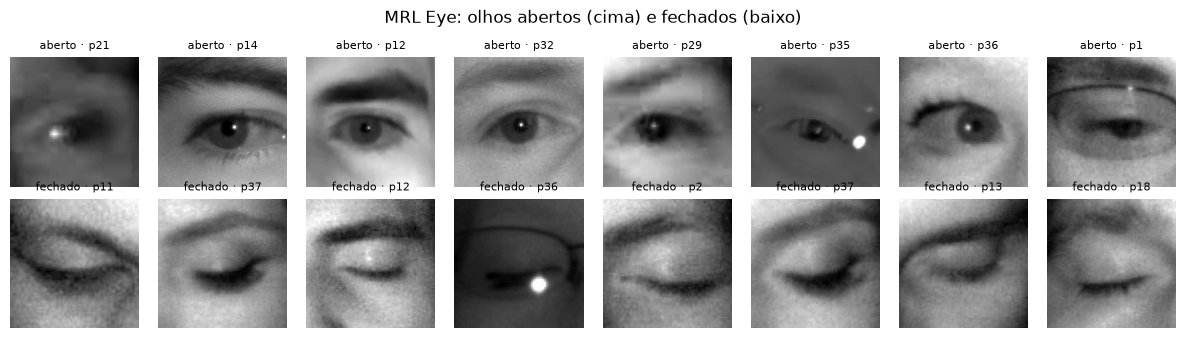

In [3]:
CAMPOS = ["pessoa", "imagem", "genero", "oculos", "aberto", "reflexo", "luz", "sensor"]

linhas = []
for arq in sorted(PASTA_MRL.glob("s*/*.png")):
    partes = arq.stem.split("_")
    linhas.append([arq] + [int(partes[0][1:])] + [int(x) for x in partes[1:]])
mrl = pd.DataFrame(linhas, columns=["arquivo"] + CAMPOS)
mrl["fechado"] = 1 - mrl["aberto"]

print(f"{len(mrl):,} imagens de {mrl.pessoa.nunique()} pessoas")
print(f"olho fechado: {mrl.fechado.mean():.1%} | com óculos: {mrl.oculos.mean():.1%} | "
      f"reflexo grande: {(mrl.reflexo == 2).mean():.1%} | luz ruim: {(mrl.luz == 0).mean():.1%}")

por_pessoa = mrl.groupby("pessoa").agg(imagens=("fechado", "size"), fechado=("fechado", "mean"))
print(f"imagens por pessoa: de {por_pessoa.imagens.min()} a {por_pessoa.imagens.max()} "
      f"(mediana {por_pessoa.imagens.median():.0f})")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([mrl[mrl.fechado == c].sample(8, random_state=SEMENTE) for c in (0, 1)])
for ax, (_, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(Image.open(r.arquivo), cmap="gray")
    ax.set_title(("fechado" if r.fechado else "aberto") + f" · p{r.pessoa}", fontsize=8)
    ax.axis("off")
plt.suptitle("MRL Eye: olhos abertos (cima) e fechados (baixo)")
plt.tight_layout(); plt.show()

### 1.3 FL3D

O FL3D é feito de 44 vídeos do NITYMED, gravados em carros reais à noite, com o rosto já recortado e um rótulo em cada frame: `alert`, `microsleep` ou `yawning`. Duas observações sobre o FL3D mudam a avaliação:

- **As piscadas foram removidas.** Os frames de piscada não estão na base, então os falsos alarmes medidos aqui são otimistas.
- **Separação por pessoa é só parcial:** usamos os 5 vídeos de validação/teste como **teste** e os outros 39 como **calibração** (onde os limiares são escolhidos). Segundo a página do FL3D, esses 5 têm 5 motoristas, dos quais 3 são inéditos e 2 também aparecem no treino dos autores, sem indicar quais. A CNN não é afetada, porque nada do FL3D a treina. O efeito fica nos limiares, que podem ter sido escolhidos com motoristas que reaparecem no teste.

In [4]:
def numero_frame(nome):
    return int(re.findall(r"\d+", nome)[0])

linhas = []
for pasta in sorted(p for p in PASTA_FL3D.iterdir() if p.is_dir()):
    anot = json.load(open(pasta / "annotations_final.json"))
    for nome, info in anot.items():
        if info["driver_state"] is not None:          # 2 frames sem rótulo
            linhas.append((pasta.name, numero_frame(nome), nome, info["driver_state"]))
fl3d = pd.DataFrame(linhas, columns=["video", "frame", "nome", "estado"]).sort_values(["video", "frame"])
fl3d = fl3d.reset_index(drop=True)

videos_teste = sorted({k.split("/")[2] for k in json.load(open(PASTA_FL3D / "annotations_holdout.json"))})
fl3d["grupo"] = np.where(fl3d.video.isin(videos_teste), "teste", "calibração")

resumo = fl3d.groupby(["grupo", "video"]).estado.value_counts().unstack(fill_value=0)
resumo["segundos"] = (fl3d.groupby(["grupo", "video"]).frame.agg(lambda f: f.max() - f.min() + 1) / FPS).round(0)
print(f"{len(fl3d):,} frames em {fl3d.video.nunique()} vídeos")
print(fl3d.groupby("grupo").estado.value_counts().unstack())
print("\nvídeos de teste:")
print(resumo.loc["teste"])
# o notebook não mostra os rostos do FL3D: o repositório não guarda imagens de pessoas

53,329 frames em 44 vídeos
estado      alert  microsleep  yawning
grupo                                 
calibração  35482        8074     4769
teste        3484         795      725

vídeos de teste:
estado        alert  microsleep  yawning  segundos
video                                             
P1042762_720   2052         632       42     124.0
P1042780_720    289           0      204      40.0
P1043081_720    293           0      298      24.0
P1043086_720    327           0      181      25.0
P1043106_720    523         163        0     105.0


## 2. Linha de base: MediaPipe + EAR + regras

Antes de treinar qualquer rede, a linha de base mede o olho com geometria. O MediaPipe devolve 478 pontos do rosto, e com 6 pontos de cada olho dá para calcular o **EAR (Eye Aspect Ratio)**:

$$\text{EAR} = \frac{\lVert p_2 - p_6 \rVert + \lVert p_3 - p_5 \rVert}{2\,\lVert p_1 - p_4 \rVert}$$

O EAR é a abertura vertical dividida pela largura do olho. Ele fica perto de 0,25–0,30 com o olho aberto e cai perto de zero quando o olho fecha.

Na mesma passada pelo vídeo, guardamos o recorte de cada olho (64×64, em cinza), que a CNN vai usar na seção 4. O cálculo leva de 10 a 30 minutos na CPU e fica em cache.

In [5]:
# pontos do MediaPipe Face Mesh: p1..p6 do EAR e o contorno de cada olho
EAR_E = [33, 160, 158, 133, 153, 144]
EAR_D = [362, 385, 387, 263, 373, 380]
CONTORNO_E = [33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246]
CONTORNO_D = [362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398]
# lábios internos: três pares verticais e os dois cantos da boca
BOCA_V = [(81, 178), (13, 14), (311, 402)]
BOCA_H = (78, 308)


def criar_detector():
    # o MediaPipe não abre caminhos com acento no Windows, então o modelo vai por memória
    opcoes = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_buffer=ARQ_MEDIAPIPE.read_bytes()),
        running_mode=vision.RunningMode.IMAGE, num_faces=1)
    return vision.FaceLandmarker.create_from_options(opcoes)


def pontos_do_rosto(detector, rgb):
    # devolve os 478 pontos em pixels, ou None se não achar rosto
    r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
    if not r.face_landmarks:
        return None
    h, w = rgb.shape[:2]
    return np.array([[q.x * w, q.y * h] for q in r.face_landmarks[0]])


def ear(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[i] for i in idx)
    return (np.linalg.norm(p2 - p6) + np.linalg.norm(p3 - p5)) / (2 * np.linalg.norm(p1 - p4))


def recortar_olho(cinza, contorno, fator=1.4):
    # quadrado centrado no olho, com lado = 1,4 x a largura do olho (parecido com o MRL)
    cx, cy = contorno.mean(axis=0)
    lado = fator * (contorno[:, 0].max() - contorno[:, 0].min())
    caixa = (int(cx - lado / 2), int(cy - lado / 2), int(cx + lado / 2), int(cy + lado / 2))
    return np.asarray(Image.fromarray(cinza).crop(caixa).resize((TAM, TAM), Image.BILINEAR))


def abertura_boca(pontos):
    # abertura vertical dos lábios / largura da boca, para um ou vários frames
    v = sum(np.linalg.norm(pontos[..., a, :] - pontos[..., b, :], axis=-1) for a, b in BOCA_V) / len(BOCA_V)
    return v / np.linalg.norm(pontos[..., BOCA_H[0], :] - pontos[..., BOCA_H[1], :], axis=-1)


def extrair_fl3d():
    arq_csv, arq_olhos, arq_pontos = CACHE / "fl3d_ear.csv", CACHE / "fl3d_olhos.npy", CACHE / "fl3d_pontos.npy"
    if arq_csv.exists() and arq_olhos.exists() and arq_pontos.exists():
        return pd.read_csv(arq_csv), np.load(arq_olhos), np.load(arq_pontos)
    detector = criar_detector()
    ears, olhos = [], np.zeros((len(fl3d), 2, TAM, TAM), np.uint8)
    pontos = np.full((len(fl3d), 478, 2), np.nan, np.float32)
    inicio = time.time()
    for i, r in enumerate(fl3d.itertuples()):
        rgb = np.asarray(Image.open(PASTA_FL3D / r.video / r.nome).convert("RGB"))
        p = pontos_do_rosto(detector, rgb)
        if p is None:
            ears.append((np.nan, np.nan, False))
            continue
        pontos[i] = p[:478]
        cinza = np.asarray(Image.fromarray(rgb).convert("L"))
        olhos[i, 0] = recortar_olho(cinza, p[CONTORNO_E])
        olhos[i, 1] = recortar_olho(cinza, p[CONTORNO_D])
        ears.append((ear(p, EAR_E), ear(p, EAR_D), True))
    print(f"{(time.time() - inicio) / len(fl3d) * 1000:.1f} ms por frame")
    tab = pd.DataFrame(ears, columns=["ear_e", "ear_d", "rosto"])
    tab.to_csv(arq_csv, index=False)
    np.save(arq_olhos, olhos)
    np.save(arq_pontos, pontos)
    return tab, olhos, pontos


tab_ear, olhos_fl3d, pontos_fl3d = extrair_fl3d()
fl3d[["ear_e", "ear_d", "rosto"]] = tab_ear[["ear_e", "ear_d", "rosto"]].values
fl3d["ear"] = fl3d[["ear_e", "ear_d"]].astype(float).mean(axis=1)
fl3d["rosto"] = fl3d["rosto"].astype(bool)
fl3d["boca"] = abertura_boca(pontos_fl3d)
print(f"rosto encontrado em {fl3d.rosto.mean():.2%} dos frames")
print(fl3d.groupby("estado").ear.describe()[["count", "mean", "50%", "std"]].round(3))

rosto encontrado em 98.51% dos frames
              count   mean    50%    std
estado                                  
alert       38368.0  0.303  0.301  0.070
microsleep   8684.0  0.091  0.082  0.047
yawning      5481.0  0.189  0.191  0.073


### 2.1 Calibração por pessoa

O EAR de olho aberto muda de pessoa para pessoa, então um limiar fixo como 0,2 falha. Cada vídeo é calibrado pelo próprio começo: o **EAR de referência é o percentil 75 dos primeiros 30 s**, e o sinal usado é `1 − EAR / referência` (0 = olho como na calibração, 1 = olho fechado). Usamos o percentil 75, e não a mediana, porque alguns vídeos já começam com microssono.

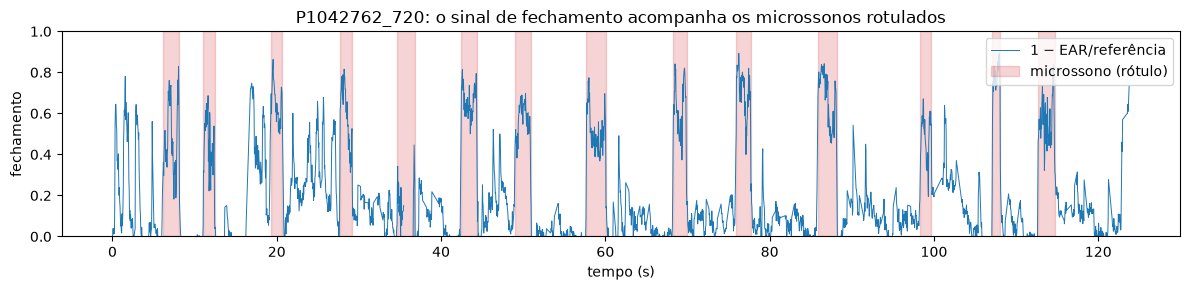

In [6]:
def referencia(d, segundos=30):
    inicio = d.frame.min()
    return d.loc[d.frame < inicio + segundos * FPS, "ear"].quantile(0.75)

ref = fl3d.groupby("video").apply(referencia, include_groups=False)
fl3d["fech_ear"] = (1 - fl3d.ear / fl3d.video.map(ref)).clip(0, 1)

v = "P1042762_720"   # vídeo de teste com microssonos
d = fl3d[fl3d.video == v]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(d.frame / FPS, d.fech_ear, lw=0.7, color="tab:blue", label="1 − EAR/referência")
ms = d.estado.eq("microsleep").values
ax.fill_between(d.frame / FPS, 0, 1, where=ms, color="tab:red", alpha=0.2, step="mid", label="microssono (rótulo)")
ax.set_xlabel("tempo (s)"); ax.set_ylabel("fechamento"); ax.set_ylim(0, 1); ax.legend(loc="upper right")
ax.set_title(f"{v}: o sinal de fechamento acompanha os microssonos rotulados")
plt.tight_layout(); plt.show()

### 2.2 Olho fechado por frame

Primeiro, a pergunta mais simples: o sinal separa os frames de microssono dos outros? O limiar é escolhido nos vídeos de calibração (maior F1) e aplicado nos de teste. Como `microsleep` é a classe rara (cerca de 17% dos frames), a métrica principal é a **AUC-PR**.

In [7]:
def limiar_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.maximum(p + r, 1e-9)
    return t[np.argmax(f1[:-1])]


def metricas_frame(d, col, limiar):
    y, s = d.estado.eq("microsleep").values, d[col].values
    p, r, f1, _ = precision_recall_fscore_support(y, s >= limiar, average="binary", zero_division=0)
    return {"AUC-PR": average_precision_score(y, s), "precisão": p, "recall": r, "F1": f1}


calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_EAR = limiar_f1(calib.estado.eq("microsleep"), calib.fech_ear)
print(f"limiar escolhido na calibração: fechamento >= {LIMIAR_EAR:.3f} "
      f"(EAR abaixo de {1 - LIMIAR_EAR:.0%} da referência)")
pd.DataFrame({"calibração": metricas_frame(calib, "fech_ear", LIMIAR_EAR),
              "teste": metricas_frame(teste, "fech_ear", LIMIAR_EAR)}).T.round(3)

limiar escolhido na calibração: fechamento >= 0.525 (EAR abaixo de 47% da referência)


,AUC-PR,precisão,recall,F1
calibração,0.834,0.774,0.789,0.782
teste,0.658,0.637,0.694,0.664


### 2.3 Do frame ao alerta: regras do Euro NCAP

Um frame com o olho fechado pode ser só uma piscada. O alerta só dispara quando o olho fica fechado **por tempo seguido**. Os limiares vêm do protocolo do Euro NCAP (pesquisa, seção Indústria):

| Nível | Olho fechado por | Alerta |
|---|---|---|
| Microssono | 1 a 2 s | som forte |
| Sono | 3 s ou mais | som urgente + "pare em local seguro" |
| Sem resposta | 6 s ou mais | máximo |

Antes de fixar o tempo mínimo, vale olhar quanto duram os microssonos do FL3D. Um **episódio** é um trecho seguido de frames `microsleep`, juntando buracos de até 0,5 s (frames removidos da base).

254 episódios de microssono | duração mediana 1.4 s | 35% com menos de 1 s | 5% com 3 s ou mais


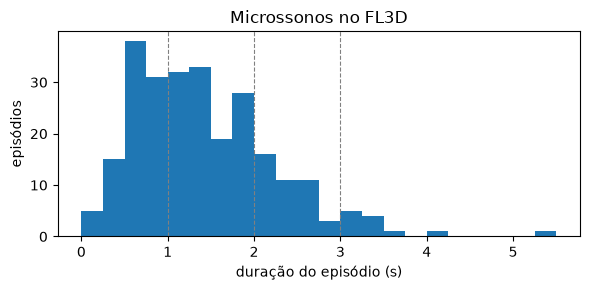

In [8]:
def trechos(mascara):
    # trechos seguidos de True -> lista de (início, fim), fim incluso
    m = np.r_[False, mascara, False].astype(int)
    d = np.diff(m)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))


def unir(lista, buraco):
    # junta trechos separados por até `buraco` frames
    saida = []
    for a, b in lista:
        if saida and a - saida[-1][1] - 1 <= buraco:
            saida[-1] = (saida[-1][0], b)
        else:
            saida.append((a, b))
    return saida


def linha_do_tempo(d):
    # um valor por frame do vídeo, incluindo os frames que a base removeu (NaN)
    tl = pd.DataFrame({"frame": np.arange(d.frame.min(), d.frame.max() + 1)})
    return tl.merge(d, on="frame", how="left")


BURACO_EP = int(0.5 * FPS)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
episodios = {v: unir(trechos(tl.estado.eq("microsleep").values), BURACO_EP) for v, tl in tempo.items()}

dur = np.array([(b - a + 1) / FPS for eps in episodios.values() for a, b in eps])
print(f"{len(dur)} episódios de microssono | duração mediana {np.median(dur):.1f} s | "
      f"{(dur < 1).mean():.0%} com menos de 1 s | {(dur >= 3).mean():.0%} com 3 s ou mais")
plt.figure(figsize=(6, 3))
plt.hist(dur, bins=np.arange(0, dur.max() + 0.25, 0.25))
for x in (1, 2, 3):
    plt.axvline(x, color="gray", ls="--", lw=0.8)
plt.xlabel("duração do episódio (s)"); plt.ylabel("episódios"); plt.title("Microssonos no FL3D")
plt.tight_layout(); plt.show()

A regra de alerta:

1. o frame conta como **fechado** quando o sinal passa do limiar da seção 2.2;
2. trechos fechados separados por até 3 frames (0,12 s) viram um só, para um frame ruim não zerar a contagem;
3. o **alerta dispara** quando um trecho fechado chega a **T segundos**, uma vez por trecho.

Um alerta é **acerto** se cai dentro de um episódio (com tolerância de 0,5 s depois do fim) e **falso alarme** se não. As métricas são as da pesquisa: recall de evento, falsos alarmes por hora de direção alerta e atraso. O T do sistema é fixo: **T = 1 s**, o limite inferior da faixa de microssono do Euro NCAP. Ele não é escolhido no FL3D, porque a base não tem piscadas: sem elas, quase nada pune um T curto, e o melhor F1 tende ao menor valor testado.

A **varredura de T** (0,4 s a 2 s) continua abaixo, só para mostrar a troca entre detectar mais e alarmar mais. Além do recall em todos os episódios, medimos o recall nos episódios de 1 s ou mais, porque T = 1 s não pretende detectar eventos mais curtos. Um alerta dentro de um episódio curto não conta como acerto nem como falso alarme nessa segunda conta.

In [9]:
BURACO_FECH = 3
TOL = int(0.5 * FPS)
T_ALERTA = 1.0   # limite inferior da faixa de microssono do Euro NCAP (1 a 2 s)


def bocejo_ativo(tl, lim, persistencia, margem):
    # só usa frames passados: boca aberta por `persistencia` frames seguidos, e mais `margem` frames depois
    alta = tl["boca"].ge(lim).astype(float)
    firme = alta.rolling(persistencia, min_periods=persistencia).sum().eq(persistencia).astype(float)
    return firme.rolling(margem + 1, min_periods=1).max().gt(0).values


def fechamento(tl, col, limiar, mediana=1, delta=0.0, manter=0, filtro=None):
    # True nos frames fechados. Os padrões reproduzem a regra simples; a seção 4.2 testa os ajustes
    # e a seção 6 testa o filtro de bocejo.
    s = tl[col]
    if manter:      # falha curta do rosto mantém o último valor
        s = s.where(~tl["rosto"].eq(False), s.ffill(limit=manter))
    if mediana > 1:  # só frames passados, para valer também ao vivo
        s = s.rolling(mediana, min_periods=1).median().where(s.notna())
    v = s.values
    if delta == 0:
        fechado = v >= limiar
    else:
        # histerese: fecha ao passar de limiar e continua fechado até cair abaixo de limiar - delta
        alto, baixo = v >= limiar, v >= limiar - delta
        fechado = np.zeros(len(v), bool)
        for a, b in trechos(baixo):
            acima = np.flatnonzero(alto[a:b + 1])
            if len(acima):
                fechado[a + acima[0]:b + 1] = True
    if filtro:      # olho fechado durante bocejo detectado não conta para o alerta
        fechado = fechado & ~bocejo_ativo(tl, **filtro)
    return fechado


def alertas(tl, col, limiar, T, **ajustes):
    fechado = fechamento(tl, col, limiar, **ajustes)
    n = int(round(T * FPS))
    # (frame do alerta, início do trecho, fim do trecho)
    return [(a + n - 1, a, b) for a, b in unir(trechos(fechado), BURACO_FECH) if b - a + 1 >= n]


def avaliar_eventos(videos, col, limiar, T, dur_min=0.0, ajustes=None):
    # dur_min: só episódios com pelo menos essa duração entram no recall. Um alerta
    # dentro de um episódio mais curto não conta como acerto nem como falso alarme.
    n_ep = acertos = falsos = falsos_bocejo = 0
    atrasos, horas_alerta, min_bocejo = [], 0.0, 0.0
    for v in videos:
        tl, eps = tempo[v], episodios[v]
        validos = {i for i, (a, b) in enumerate(eps) if (b - a + 1) / FPS >= dur_min}
        detectado = set()
        for al, ini, fim in alertas(tl, col, limiar, T, **(ajustes or {})):
            dentro = [i for i, (a, b) in enumerate(eps) if a - TOL <= al <= b + TOL]
            if not dentro:
                falsos += 1
                # ligado a bocejo: há frame rotulado como bocejo no trecho ou a até 2 s dele
                falsos_bocejo += tl.estado.iloc[max(ini - 2 * FPS, 0):fim + 2 * FPS + 1].eq("yawning").any()
            for i in dentro:
                if i in validos and i not in detectado:
                    detectado.add(i)
                    atrasos.append(max(al - eps[i][0], 0) / FPS)
        n_ep += len(validos)
        acertos += len(detectado)
        horas_alerta += tl.estado.eq("alert").sum() / FPS / 3600
        min_bocejo += tl.estado.eq("yawning").sum() / FPS / 60
    return {"T (s)": T, "episódios": n_ep, "acertos": acertos, "recall de evento": acertos / max(n_ep, 1),
            "falsos alarmes": falsos, "falsos em bocejo": falsos_bocejo, "falsos fora de bocejo": falsos - falsos_bocejo,
            "fora de bocejo/hora em alerta": (falsos - falsos_bocejo) / max(horas_alerta, 1e-9),
            "em bocejo/min de bocejo": falsos_bocejo / max(min_bocejo, 1e-9),
            "atraso mediano (s)": np.median(atrasos) if atrasos else np.nan,
            "horas alerta": horas_alerta, "min bocejo": min_bocejo}


def varrer_T(videos, col, limiar, Ts=(0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0)):
    # só informa o efeito de cada T: o T do sistema é T_ALERTA, que não sai desta tabela
    tab = pd.DataFrame([avaliar_eventos(videos, col, limiar, T) for T in Ts])
    # F1 de evento: recall de evento x fração dos alertas que acertam
    precisao = tab["acertos"] / np.maximum(tab["acertos"] + tab["falsos alarmes"], 1)
    tab["F1 evento"] = np.where(tab["acertos"] > 0,
                                2 * tab["recall de evento"] * precisao
                                / np.maximum(tab["recall de evento"] + precisao, 1e-9), 0.0)
    return tab


videos_calib = sorted(fl3d.loc[fl3d.grupo == "calibração", "video"].unique())
COLUNAS_T = ["T (s)", "acertos", "episódios", "recall de evento", "falsos alarmes", "F1 evento"]
print("Varredura de T com o EAR, na calibração:")
display(varrer_T(videos_calib, "fech_ear", LIMIAR_EAR)[COLUNAS_T].round(3))
print("Varredura de T com o EAR, no teste:")
display(varrer_T(videos_teste, "fech_ear", LIMIAR_EAR)[COLUNAS_T].round(3))


Varredura de T com o EAR, na calibração:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento
0,0.4,173,228,0.759,56,0.757
1,0.6,155,228,0.680,37,0.738
2,0.8,130,228,0.570,27,0.675
3,1.0,114,228,0.500,22,0.626
4,1.2,96,228,0.421,17,0.563
5,1.5,70,228,0.307,11,0.453
6,2.0,35,228,0.154,5,0.261


Varredura de T com o EAR, no teste:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento
0,0.4,22,26,0.846,6,0.815
1,0.6,14,26,0.538,3,0.651
2,0.8,10,26,0.385,3,0.513
3,1.0,7,26,0.269,3,0.389
4,1.2,5,26,0.192,3,0.294
5,1.5,3,26,0.115,3,0.188
6,2.0,0,26,0.000,3,0.000


In [10]:
res_ear = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA)
res_ear_longos = avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA, dur_min=T_ALERTA)
pd.DataFrame({"EAR, T = 1 s, todos os episódios": res_ear,
              "EAR, T = 1 s, episódios de 1 s ou mais": res_ear_longos}).T.round(3)


,T (s),episódios,acertos,recall de evento,falsos alarmes,falsos em bocejo,falsos fora de bocejo,fora de bocejo/hora em alerta,em bocejo/min de bocejo,atraso mediano (s),horas alerta,min bocejo
"EAR, T = 1 s, todos os episódios",1.0,26.0,7.0,0.269,3.0,3.0,0.0,0.0,6.207,1.0,0.039,0.483
"EAR, T = 1 s, episódios de 1 s ou mais",1.0,14.0,7.0,0.500,3.0,3.0,0.0,0.0,6.207,1.0,0.039,0.483


### Observações da linha de base

- **O MediaPipe funciona bem nesses vídeos:** acha o rosto em 98,5% dos frames, a 10 a 24 ms por frame na CPU, contando a leitura da imagem. O tempo maior é da primeira leitura dos arquivos.
- **O EAR separa bem os estados:** a mediana é 0,30 em alerta, 0,08 em microssono e 0,19 em bocejo. O bocejo aperta o olho, e por isso é a principal fonte de confusão.
- **Por frame, o teste cai em relação à calibração** (AUC-PR de 0,83 para 0,66). Parte dos motoristas do teste é nova, então o limiar pode servir menos neles, mas o teste é pequeno e não dá para separar as causas.
- **Com T = 1 s, o EAR acha 7 de 26 episódios no teste, com 3 falsos alarmes.** Só 14 dos 26 duram 1 s ou mais, e neles o recall é de 7 de 14. Na calibração, são 114 de 228 episódios, com 22 falsos alarmes.
- **T = 0,4 s acharia 22 de 26, mas esse número é otimista.** O FL3D tirou as piscadas, e uma piscada longa (0,3 a 0,4 s) dispararia o alerta. Além disso, 0,4 s fica abaixo do mínimo de 1 s das definições de microssono da pesquisa.
- **O rótulo do FL3D é mais amplo que a regra:** 35% dos episódios da base duram menos de 1 s, e só 5% chegam a 3 s. O recall em todos os episódios cobra eventos que T = 1 s não pretende detectar.
- **Os falsos alarmes por hora não são confiáveis aqui:** o teste tem só 2,3 minutos de direção em alerta. Os 3 falsos alarmes do EAR aqui estão ligados a bocejos, e a seção 6 os analisa.

### 2.4 Os três níveis do alerta

A mesma lógica dá os três níveis do Euro NCAP. Cada trecho fechado recebe o nível mais alto que alcança. No FL3D quase não há trechos de 3 s ou mais, então os níveis "sono" e "sem resposta" ficam implementados mas pouco testados aqui. Eles serão testados na demo com a webcam, com sono encenado.

In [11]:
NIVEIS = [(6.0, "sem resposta"), (3.0, "sono"), (1.0, "microssono")]


def nivel(duracao_s):
    for minimo, nome in NIVEIS:
        if duracao_s >= minimo:
            return nome
    return None


contagem = {}
for v in fl3d.video.unique():
    fechado = (tempo[v]["fech_ear"] >= LIMIAR_EAR).fillna(False).values
    for a, b in unir(trechos(fechado), BURACO_FECH):
        n = nivel((b - a + 1) / FPS)
        if n:
            contagem[n] = contagem.get(n, 0) + 1
print("trechos fechados por nível, nos 44 vídeos:", contagem)

trechos fechados por nível, nos 44 vídeos: {'microssono': 140, 'sono': 8}


## 3. CNN de olho: MobileNetV3 com fine-tuning

O EAR depende de 6 pontos e erra quando o MediaPipe erra a pálpebra (óculos, reflexo, cabeça de lado). A CNN olha o recorte inteiro do olho e devolve P(olho fechado).

- **Modelo:** MobileNetV3-Small pré-treinada no ImageNet, com a última camada trocada por 1 saída. É pequena (cerca de 1,5 M de parâmetros) e roda em tempo real na CPU.
- **Dados:** MRL Eye, em cinza, 64×64, repetido nos 3 canais.
- **Separação por pessoa:** as 37 pessoas são divididas em treino, validação e teste **antes** de qualquer coisa, então nenhum rosto do teste aparece no treino.

In [12]:
def carregar_mrl():
    arq = CACHE / f"mrl_{TAM}.npy"
    if arq.exists():
        return np.load(arq)
    x = np.stack([np.asarray(Image.open(a).convert("L").resize((TAM, TAM), Image.BILINEAR))
                  for a in mrl.arquivo])
    np.save(arq, x)
    return x


x_mrl = carregar_mrl()
y_mrl = mrl.fechado.values.astype(np.float32)

# 1º corte: teste (~20% das pessoas); 2º corte: validação (~15% do resto)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_resto, idx_te = next(gss.split(x_mrl, y_mrl, groups=mrl.pessoa))
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEMENTE)
i_tr, i_va = next(gss.split(idx_resto, groups=mrl.pessoa.values[idx_resto]))
idx_tr, idx_va = idx_resto[i_tr], idx_resto[i_va]

pessoas = {n: set(mrl.pessoa.values[i]) for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]}
assert not (pessoas["treino"] & pessoas["validação"]) and not (pessoas["treino"] & pessoas["teste"]) \
    and not (pessoas["validação"] & pessoas["teste"]), "uma pessoa caiu em duas partições"
for n, i in [("treino", idx_tr), ("validação", idx_va), ("teste", idx_te)]:
    print(f"{n:10s}: {len(i):6,} imagens, {len(pessoas[n]):2d} pessoas, {y_mrl[i].mean():.1%} fechados, "
          f"{mrl.oculos.values[i].mean():.0%} com óculos")
print("pessoas no teste:", sorted(int(p) for p in pessoas["teste"]))

treino    : 54,197 imagens, 24 pessoas, 49.2% fechados, 30% com óculos
validação :  6,559 imagens,  5 pessoas, 54.2% fechados, 19% com óculos
teste     : 24,142 imagens,  8 pessoas, 48.5% fechados, 27% com óculos
pessoas no teste: [5, 7, 14, 18, 26, 27, 30, 36]


### 3.1 Treino

O aumento de dados roda na GPU, por lote: espelhamento horizontal, brilho, contraste, gama, pequeno deslocamento e ruído. A ideia é aproximar o infravermelho do MRL da webcam RGB noturna do FL3D. O treino usa AdamW com taxa cosseno e guarda o modelo da época com menor perda na validação. O modelo fica em cache em `data/modelos/`.

In [13]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
DESVIO = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def preparar(x_uint8):
    # uint8 [B, H, W] -> float normalizado [B, 3, H, W]
    x = x_uint8.to(DEVICE, non_blocking=True).float().div(255).unsqueeze(1)
    return x


def normalizar(x):
    return (x.repeat(1, 3, 1, 1) - MEDIA) / DESVIO


def aumentar(x):
    B = x.shape[0]
    def u(a, b):
        return torch.empty(B, 1, 1, 1, device=x.device).uniform_(a, b)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(-1), x)
    x = x.clamp(1e-4, 1) ** u(0.7, 1.4)                                   # gama
    m = x.mean(dim=(2, 3), keepdim=True)
    x = (x - m) * u(0.7, 1.3) + m + u(-0.15, 0.15)                        # contraste e brilho
    dx, dy = np.random.randint(-4, 5, size=2)
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))             # deslocamento
    x = x + torch.randn_like(x) * u(0, 0.04)                               # ruído
    return x.clamp(0, 1)


def criar_modelo():
    m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)
    return m.to(DEVICE)


@torch.no_grad()
def prever(modelo, x_uint8, lote=1024, norm=normalizar):
    modelo.eval()
    saidas = []
    for i in range(0, len(x_uint8), lote):
        xb = norm(preparar(torch.from_numpy(x_uint8[i:i + lote])))
        saidas.append(torch.sigmoid(modelo(xb)).squeeze(1).cpu())
    return torch.cat(saidas).numpy()


def treinar(nome, i_tr, i_va, epocas=10, lote=256, lr=1e-3,
            criar=criar_modelo, norm=normalizar, semente=SEMENTE, detalhar=True):
    arq = PASTA_MODELOS / f"{nome}.pt"
    modelo = criar()
    if arq.exists():
        salvo = torch.load(arq, map_location=DEVICE)
        modelo.load_state_dict(salvo["pesos"])
        print(f"{nome}: carregado do cache (melhor época {salvo['melhor']})")
        return modelo, salvo["historico"]

    torch.manual_seed(semente); np.random.seed(semente)
    # o MRL em 64x64 cabe inteiro na GPU (~250 MB), o que evita copiar lote a lote
    x_tr, y_tr = torch.from_numpy(x_mrl[i_tr]).to(DEVICE), torch.from_numpy(y_mrl[i_tr]).to(DEVICE)
    x_va, y_va = torch.from_numpy(x_mrl[i_va]).to(DEVICE), torch.from_numpy(y_mrl[i_va]).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    passos = epocas * int(np.ceil(len(x_tr) / lote))
    agenda = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=passos, pct_start=0.15)
    perda_fn = nn.BCEWithLogitsLoss()
    hist = {k: [] for k in ("perda_tr", "acc_tr", "perda_va", "acc_va")}
    melhor, melhor_perda, melhor_pesos = 0, np.inf, None

    for ep in range(1, epocas + 1):
        modelo.train()
        ordem = torch.randperm(len(x_tr), device=DEVICE)
        soma = acertos = 0
        t0 = time.time()
        for i in range(0, len(ordem), lote):
            j = ordem[i:i + lote]
            xb = norm(aumentar(preparar(x_tr[j])))
            yb = y_tr[j]
            logit = modelo(xb).squeeze(1)
            perda = perda_fn(logit, yb)
            opt.zero_grad(); perda.backward(); opt.step(); agenda.step()
            soma += perda.item() * len(j)
            acertos += ((logit > 0).float() == yb).sum().item()
        modelo.eval()
        with torch.no_grad():
            logit_va = torch.cat([modelo(norm(preparar(x_va[i:i + 1024]))).squeeze(1)
                                  for i in range(0, len(x_va), 1024)])
            perda_va = perda_fn(logit_va, y_va).item()
            acc_va = ((logit_va > 0).float() == y_va).float().mean().item()
        hist["perda_tr"].append(soma / len(x_tr)); hist["acc_tr"].append(acertos / len(x_tr))
        hist["perda_va"].append(perda_va); hist["acc_va"].append(acc_va)
        if perda_va < melhor_perda:
            melhor, melhor_perda = ep, perda_va
            melhor_pesos = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        if detalhar:
            print(f"época {ep:2d}: perda {hist['perda_tr'][-1]:.4f} / val {perda_va:.4f} | "
                  f"acc {hist['acc_tr'][-1]:.4f} / val {acc_va:.4f} | {time.time() - t0:.0f} s")

    modelo.load_state_dict(melhor_pesos)
    torch.save({"pesos": melhor_pesos, "historico": hist, "melhor": melhor}, arq)
    print(f"melhor época: {melhor}")
    return modelo, hist


cnn, hist = treinar("cnn_olho_por_pessoa", idx_tr, idx_va)

cnn_olho_por_pessoa: carregado do cache (melhor época 8)


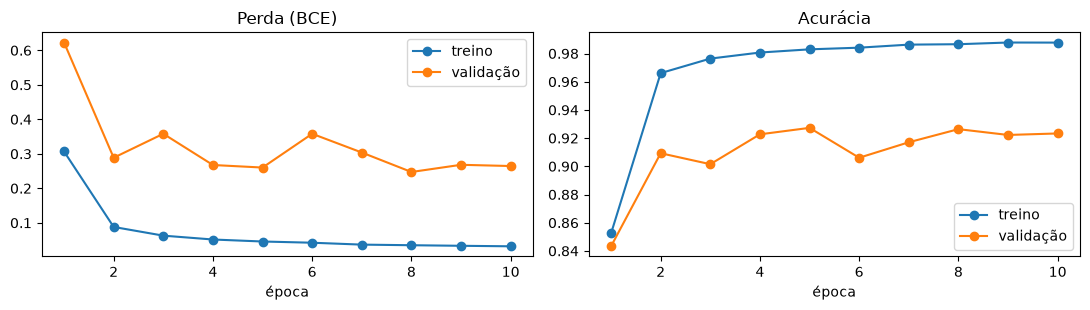

diferença treino − validação na última época: +0.0644 de acurácia


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ep = np.arange(1, len(hist["perda_tr"]) + 1)
axes[0].plot(ep, hist["perda_tr"], "o-", label="treino"); axes[0].plot(ep, hist["perda_va"], "o-", label="validação")
axes[0].set_title("Perda (BCE)"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(ep, hist["acc_tr"], "o-", label="treino"); axes[1].plot(ep, hist["acc_va"], "o-", label="validação")
axes[1].set_title("Acurácia"); axes[1].set_xlabel("época"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"diferença treino − validação na última época: "
      f"{hist['acc_tr'][-1] - hist['acc_va'][-1]:+.4f} de acurácia")

### 3.2 Teste em pessoas novas

O limiar de P(fechado) é escolhido na validação (maior F1) e aplicado no teste. Além do total, o resultado sai **por pessoa** e por condição (óculos, reflexo, luz), porque a média esconde quem o modelo erra.

limiar (validação): 0.502
teste: acurácia 0.9697 | precisão 0.9590 | recall 0.9793 | F1 0.9691 | AUC-PR 0.9943


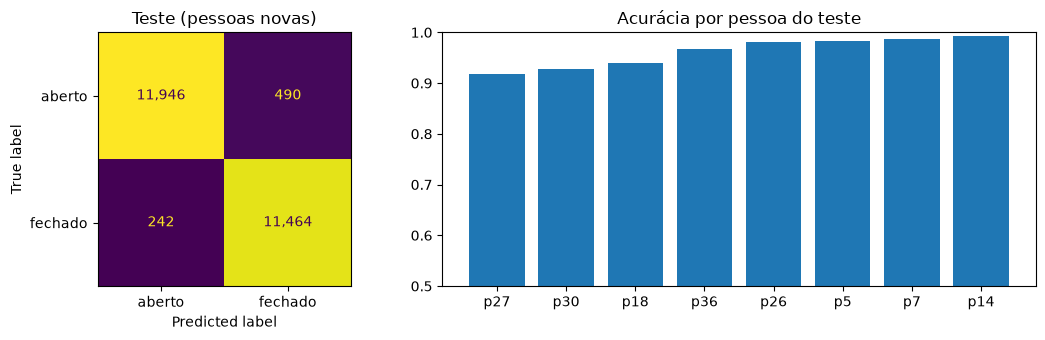

por pessoa: média 0.9622, desvio 0.0293, pior 0.9188


acurácia  imagens
óculos  com        0.9264     6614
        sem        0.9860    17528
reflexo grande     0.8915     3244
        nenhum     0.9822    19312
        pequeno    0.9773     1586
luz     boa        0.9811     8627
        ruim       0.9633    15515

In [15]:
p_va, p_te = prever(cnn, x_mrl[idx_va]), prever(cnn, x_mrl[idx_te])
LIMIAR_CNN_MRL = limiar_f1(y_mrl[idx_va], p_va)
y_te = y_mrl[idx_te]
prev_te = (p_te >= LIMIAR_CNN_MRL).astype(int)
pr, rc, f1, _ = precision_recall_fscore_support(y_te, prev_te, average="binary")
print(f"limiar (validação): {LIMIAR_CNN_MRL:.3f}")
print(f"teste: acurácia {(prev_te == y_te).mean():.4f} | precisão {pr:.4f} | recall {rc:.4f} | "
      f"F1 {f1:.4f} | AUC-PR {average_precision_score(y_te, p_te):.4f}")

te = mrl.iloc[idx_te].assign(acerto=(prev_te == y_te))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1.6]})
ConfusionMatrixDisplay(confusion_matrix(y_te, prev_te), display_labels=["aberto", "fechado"]).plot(
    ax=axes[0], colorbar=False, values_format=",")
axes[0].set_title("Teste (pessoas novas)")
acc_p = te.groupby("pessoa").acerto.mean().sort_values()
axes[1].bar([f"p{p}" for p in acc_p.index], acc_p.values)
axes[1].set_ylim(min(0.5, acc_p.min() - 0.05), 1); axes[1].set_title("Acurácia por pessoa do teste")
plt.tight_layout(); plt.show()
print(f"por pessoa: média {acc_p.mean():.4f}, desvio {acc_p.std():.4f}, pior {acc_p.min():.4f}")

cond = pd.concat({
    "óculos": te.groupby(te.oculos.map({0: "sem", 1: "com"})).acerto.agg(["mean", "size"]),
    "reflexo": te.groupby(te.reflexo.map({0: "nenhum", 1: "pequeno", 2: "grande"})).acerto.agg(["mean", "size"]),
    "luz": te.groupby(te.luz.map({0: "ruim", 1: "boa"})).acerto.agg(["mean", "size"]),
}).rename(columns={"mean": "acurácia", "size": "imagens"})
cond.round(4)

### Observações da CNN

- **Em 8 pessoas novas:** 97,0% de acurácia, F1 de 0,969 e AUC-PR de 0,994. A pior pessoa fica em 91,9%.
- **Os pontos fracos são óculos (92,6%) e reflexo grande (89,2%),** contra 98,6% sem óculos e 98,2% sem reflexo. É o mesmo problema que a pesquisa aponta para câmeras no carro.
- **Overfitting:** o treino chega a 98,8% e a validação para em cerca de 92%. A validação tem só 5 pessoas, e o teste, com outras 8, fica em 97,0%, então a diferença entre grupos de pessoas pesa bastante. O modelo guardado é o da época com menor perda na validação (época 8).

### 3.3 Quanto o vazamento inflaria o resultado

A pesquisa avisa que dividir imagens ao acaso põe o mesmo rosto no treino e no teste. Para medir isso, a mesma receita é treinada com divisão aleatória (mesmos tamanhos) e as duas notas de teste são comparadas.

In [16]:
ss = ShuffleSplit(n_splits=1, test_size=len(idx_te) / len(x_mrl), random_state=SEMENTE)
idx_resto_a, idx_te_a = next(ss.split(x_mrl))
ss = ShuffleSplit(n_splits=1, test_size=len(idx_va) / len(idx_resto_a), random_state=SEMENTE)
i_tr_a, i_va_a = next(ss.split(idx_resto_a))
cnn_aleat, _ = treinar("cnn_olho_aleatoria", idx_resto_a[i_tr_a], idx_resto_a[i_va_a])

lim_a = limiar_f1(y_mrl[idx_resto_a[i_va_a]], prever(cnn_aleat, x_mrl[idx_resto_a[i_va_a]]))
acc_aleat = ((prever(cnn_aleat, x_mrl[idx_te_a]) >= lim_a) == y_mrl[idx_te_a]).mean()
acc_pessoa = (prev_te == y_te).mean()
print(f"divisão aleatória: {acc_aleat:.4f} | divisão por pessoa: {acc_pessoa:.4f} | "
      f"diferença: {acc_aleat - acc_pessoa:+.4f}")

cnn_olho_aleatoria: carregado do cache (melhor época 10)


divisão aleatória: 0.9896 | divisão por pessoa: 0.9697 | diferença: +0.0199


Com divisão aleatória a nota seria 99,0%, ou 2,0 pontos acima da divisão por pessoa. A diferença é pequena porque o estado do olho é uma tarefa fácil. Em sonolência, onde o modelo pode decorar o jeito de cada pessoa, a pesquisa mostra quedas muito maiores. A divisão por pessoa continua sendo a regra em todo o projeto.

## 4. CNN no vídeo: trocando o EAR pela CNN

Agora a CNN treinada no MRL (infravermelho, só o olho) recebe os recortes de olho do FL3D (webcam RGB à noite, em carro real), que ela nunca viu. O sinal de fechamento passa a ser a média de P(fechado) dos dois olhos, e o resto do sistema é igual: limiar escolhido na calibração, T = 1 s e resultado no teste.

CNN: limiar 0.506 (escolhido na calibração), T = 1.0 s (Euro NCAP)


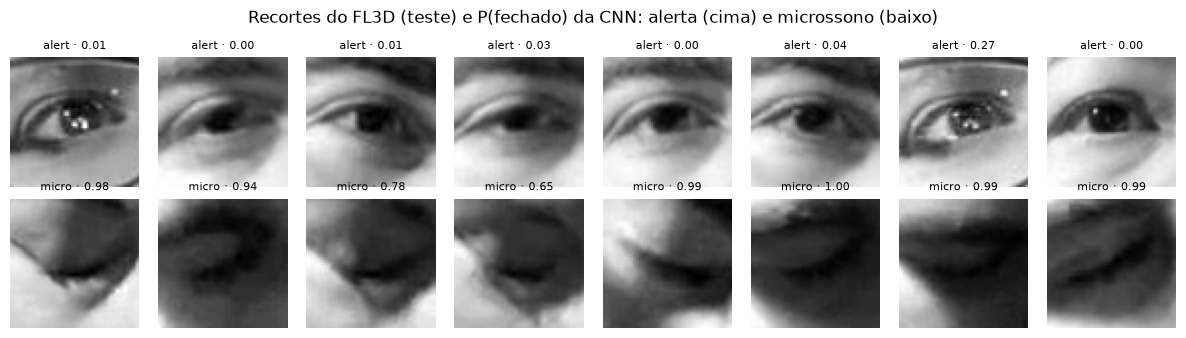

In [17]:
p_olhos = prever(cnn, olhos_fl3d.reshape(-1, TAM, TAM)).reshape(-1, 2)
fl3d["fech_cnn"] = np.where(fl3d.rosto, p_olhos.mean(axis=1), np.nan)
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}

calib = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
teste = fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
LIMIAR_CNN = limiar_f1(calib.estado.eq("microsleep"), calib.fech_cnn)
print(f"CNN: limiar {LIMIAR_CNN:.3f} (escolhido na calibração), T = {T_ALERTA} s (Euro NCAP)")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
amostra = pd.concat([teste[teste.estado == e].sample(8, random_state=SEMENTE) for e in ("alert", "microsleep")])
for ax, (i, r) in zip(axes.flat, amostra.iterrows()):
    ax.imshow(olhos_fl3d[i, 0], cmap="gray")
    ax.set_title(f"{r.estado[:5]} · {r.fech_cnn:.2f}", fontsize=8); ax.axis("off")
plt.suptitle("Recortes do FL3D (teste) e P(fechado) da CNN: alerta (cima) e microssono (baixo)")
plt.tight_layout(); plt.show()

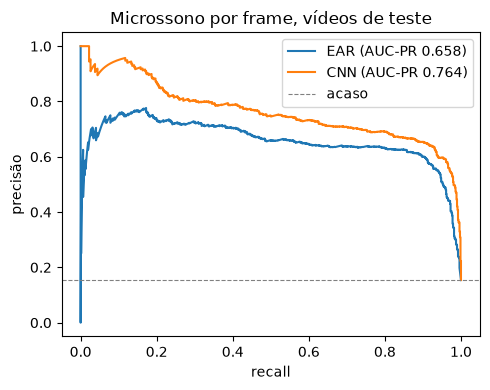

,AUC-PR,precisão,recall,F1
EAR (frame),0.658,0.637,0.694,0.664
CNN (frame),0.764,0.629,0.931,0.751


,T (s),episódios,acertos,recall de evento,falsos alarmes,falsos em bocejo,falsos fora de bocejo,fora de bocejo/hora em alerta,em bocejo/min de bocejo,atraso mediano (s),horas alerta,min bocejo
"EAR, todos os episódios",1.0,26.0,7.0,0.269,3.0,3.0,0.0,0.000,6.207,1.00,0.039,0.483
"CNN, todos os episódios",1.0,26.0,13.0,0.500,6.0,3.0,3.0,77.497,6.207,0.96,0.039,0.483
"EAR, episódios de 1 s ou mais",1.0,14.0,7.0,0.500,3.0,3.0,0.0,0.000,6.207,1.00,0.039,0.483
"CNN, episódios de 1 s ou mais",1.0,14.0,13.0,0.929,6.0,3.0,3.0,77.497,6.207,0.96,0.039,0.483


Varredura de T com a CNN, na calibração:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento
0,0.4,188,228,0.825,147,0.668
1,0.6,160,228,0.702,96,0.661
2,0.8,138,228,0.605,74,0.627
3,1.0,111,228,0.487,55,0.563
4,1.2,95,228,0.417,41,0.522
5,1.5,64,228,0.281,26,0.403
6,2.0,32,228,0.140,14,0.234


Varredura de T com a CNN, no teste:


,T (s),acertos,episódios,recall de evento,falsos alarmes,F1 evento
0,0.4,22,26,0.846,16,0.688
1,0.6,19,26,0.731,8,0.717
2,0.8,16,26,0.615,7,0.653
3,1.0,13,26,0.500,6,0.578
4,1.2,12,26,0.462,3,0.585
5,1.5,9,26,0.346,2,0.486
6,2.0,2,26,0.077,1,0.138


Teste: T = 0,4 s é otimista, porque a base não tem piscadas; T = 1 s é o do sistema


acertos  episódios  recall de evento  falsos alarmes
EAR 0.4     22.0       26.0             0.846             6.0
    1.0      7.0       26.0             0.269             3.0
    2.0      0.0       26.0             0.000             3.0
CNN 0.4     22.0       26.0             0.846            16.0
    1.0     13.0       26.0             0.500             6.0
    2.0      2.0       26.0             0.077             1.0

In [18]:
quadro = pd.DataFrame({
    "EAR (frame)": metricas_frame(teste, "fech_ear", LIMIAR_EAR),
    "CNN (frame)": metricas_frame(teste, "fech_cnn", LIMIAR_CNN),
}).T
eventos = pd.DataFrame({
    "EAR, todos os episódios": avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA),
    "CNN, todos os episódios": avaliar_eventos(videos_teste, "fech_cnn", LIMIAR_CNN, T_ALERTA),
    "EAR, episódios de 1 s ou mais": avaliar_eventos(videos_teste, "fech_ear", LIMIAR_EAR, T_ALERTA, dur_min=T_ALERTA),
    "CNN, episódios de 1 s ou mais": avaliar_eventos(videos_teste, "fech_cnn", LIMIAR_CNN, T_ALERTA, dur_min=T_ALERTA),
}).T

fig, ax = plt.subplots(figsize=(5, 4))
for col, nome in [("fech_ear", "EAR"), ("fech_cnn", "CNN")]:
    p, r, _ = precision_recall_curve(teste.estado.eq("microsleep"), teste[col])
    ax.plot(r, p, label=f"{nome} (AUC-PR {average_precision_score(teste.estado.eq('microsleep'), teste[col]):.3f})")
ax.axhline(teste.estado.eq("microsleep").mean(), color="gray", ls="--", lw=0.8, label="acaso")
ax.set_xlabel("recall"); ax.set_ylabel("precisão"); ax.set_title("Microssono por frame, vídeos de teste")
ax.legend(); plt.tight_layout(); plt.show()

display(quadro.round(3))
display(eventos.round(3))
print("Varredura de T com a CNN, na calibração:")
display(varrer_T(videos_calib, "fech_cnn", LIMIAR_CNN)[COLUNAS_T].round(3))
print("Varredura de T com a CNN, no teste:")
display(varrer_T(videos_teste, "fech_cnn", LIMIAR_CNN)[COLUNAS_T].round(3))

lado_a_lado = {(nome, T): avaliar_eventos(videos_teste, col, lim, T)
               for nome, col, lim in [("EAR", "fech_ear", LIMIAR_EAR), ("CNN", "fech_cnn", LIMIAR_CNN)]
               for T in (0.4, 1.0, 2.0)}
print("Teste: T = 0,4 s é otimista, porque a base não tem piscadas; T = 1 s é o do sistema")
display(pd.DataFrame(lado_a_lado).T[["acertos", "episódios", "recall de evento", "falsos alarmes"]].round(3))


### 4.1 Olho fechado ou microssono?

A CNN aprendeu **olho fechado**, e o rótulo do FL3D é **microssono**. Os dois não são a mesma coisa: um bocejo aperta o olho, e um olhar para baixo fecha a pálpebra. Para ver onde cada sinal erra, a tabela mostra o sinal médio por estado nos vídeos de teste.

In [19]:
teste.groupby("estado")[["fech_ear", "fech_cnn"]].agg(["mean", "median"]).round(3)

fech_ear        fech_cnn       
               mean median     mean median
estado                                    
alert         0.107  0.070    0.100  0.014
microsleep    0.598  0.611    0.851  0.942
yawning       0.342  0.289    0.334  0.123

### Observações da CNN no vídeo

- **A CNN funciona fora do domínio de treino, com ressalvas.** Treinada em infravermelho de laboratório, ela chega a F1 de 0,75 por frame na câmera noturna, contra 0,66 do EAR, com recall de 0,93 contra 0,69 e AUC-PR de 0,76 contra 0,66.
- **Com T = 1 s, no teste, a CNN acha mais e também alarma mais:** 13 de 26 episódios contra 7 de 26 do EAR, com 6 falsos alarmes contra 3. Nos episódios de 1 s ou mais, são 13 de 14 contra 7 de 14.
- **A vantagem não se repete na calibração.** Lá, com T = 1 s, os dois quase empatam (111 e 114 de 228 episódios), e a CNN dá mais que o dobro de falsos alarmes (55 contra 22). Como o teste tem só 2 vídeos com microssono, os dados não mostram que a CNN é melhor que o EAR.
- **O resultado varia entre treinos.** Com a mesma semente, em outra GPU, a mesma receita deu AUC-PR de 0,65 no vídeo, contra 0,76 aqui, e 11 falsos alarmes com T = 0,4 s, contra 16. Uma diferença desse tamanho não deve ser lida como efeito de outra mudança sem repetir o treino.
- **A CNN se confunde menos com o bocejo na maioria dos frames** (mediana 0,12, contra 0,29 do EAR), mas alguns bocejos dão P(fechado) alta.
- **O recorte piora justamente no microssono.** Quando a cabeça cai, o quadrado pega pálpebra e bochecha borradas (figura acima). Parte do acerto pode vir de "não estou vendo um olho aberto", e não de "olho fechado". Alinhar o recorte pela linha dos olhos é o próximo ajuste.

### 4.2 Dá para melhorar o sinal com T = 1 s?

Com T fixo em 1 s, um trecho fechado precisa durar 1 s sem quebrar. Se o sinal oscila em volta do limiar, a contagem recomeça. Testamos quatro ajustes, sem refazer o MediaPipe, aplicados igualmente ao EAR e à CNN:

- **Limiar de evento:** escolhido pelo F1 de evento com T = 1 s, em vez do F1 por frame.
- **Filtro de mediana:** de 5 ou 7 frames, usando só frames passados, para valer também ao vivo. O custo é um pequeno atraso.
- **Histerese:** um limiar para fechar e outro, mais baixo, para continuar fechado.
- **Manter o rosto:** falhas de até 0,5 s do MediaPipe mantêm o último valor, em vez de quebrar a contagem.

Para não contaminar o teste, a configuração é escolhida só nos 39 vídeos de calibração, com alvo nos episódios de 1 s ou mais. Entre configurações quase empatadas (F1 a até 0,005 da melhor), fica a mais simples. A tabela mostra o efeito de cada ajuste, reescolhendo o limiar em cada linha. O limite desse ajuste é o mesmo da escolha de T: a base não tem piscadas, então juntar trechos e baixar o limiar podem custar mais falsos alarmes do que aparece aqui.

In [20]:
GRADE_LIMIAR = np.round(np.arange(0.20, 0.91, 0.05), 2)
GRADE_AJUSTES = [dict(mediana=m, delta=d, manter=k)
                 for m in (1, 5, 7) for d in (0.0, 0.1, 0.2) for k in (0, int(0.5 * FPS))]
SINAIS = {"EAR": ("fech_ear", LIMIAR_EAR), "CNN": ("fech_cnn", LIMIAR_CNN)}
ORIGINAL = dict(mediana=1, delta=0.0, manter=0)


def f1_evento(acertos, n_ep, falsos):
    recall = acertos / max(n_ep, 1)
    precisao = acertos / max(acertos + falsos, 1)
    return 2 * recall * precisao / max(recall + precisao, 1e-9)


def varrer_ajustes(col):
    # só calibração, com T fixo; o alvo são os episódios de 1 s ou mais
    linhas = []
    for aj in GRADE_AJUSTES:
        for lim in GRADE_LIMIAR:
            r = avaliar_eventos(videos_calib, col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            linhas.append({**aj, "limiar": lim, "acertos": r["acertos"], "episódios": r["episódios"],
                           "falsos": r["falsos alarmes"],
                           "F1": f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"])})
    return pd.DataFrame(linhas)


def escolher_config(grade, folga=0.005):
    # entre configurações quase empatadas, fica a mais simples, para não sobreajustar
    perto = grade[grade.F1 >= grade.F1.max() - folga]
    return perto.sort_values(["mediana", "delta", "manter", "F1"], ascending=[True, True, True, False]).iloc[0]


def efeito_dos_ajustes(col, lim_original, grade):
    r = avaliar_eventos(videos_calib, col, lim_original, T_ALERTA, dur_min=T_ALERTA)
    linhas = [{"variante": "regra original", **ORIGINAL, "limiar": lim_original, "acertos": r["acertos"],
               "episódios": r["episódios"], "falsos": r["falsos alarmes"],
               "F1": f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"])}]
    so = {"só limiar de evento": (grade.mediana == 1) & (grade.delta == 0) & (grade.manter == 0),
          "+ mediana": (grade.mediana > 1) & (grade.delta == 0) & (grade.manter == 0),
          "+ histerese": (grade.mediana == 1) & (grade.delta > 0) & (grade.manter == 0),
          "+ manter rosto": (grade.mediana == 1) & (grade.delta == 0) & (grade.manter > 0),
          "todas as combinações": grade.F1 > -1}
    for nome, m in so.items():
        melhor = grade[m].sort_values("F1", ascending=False).iloc[0]
        linhas.append({"variante": nome, **melhor.to_dict()})
    return pd.DataFrame(linhas)


# os padrões precisam reproduzir a regra original
for nome, (col, lim) in SINAIS.items():
    a = avaliar_eventos(videos_teste, col, lim, T_ALERTA)
    b = avaliar_eventos(videos_teste, col, lim, T_ALERTA, ajustes=ORIGINAL)
    assert (a["acertos"], a["falsos alarmes"]) == (b["acertos"], b["falsos alarmes"]), nome

CONFIG = {}
for nome, (col, lim) in SINAIS.items():
    grade = varrer_ajustes(col)
    CONFIG[nome] = escolher_config(grade)
    print(f"{nome}, calibração, T = 1 s, episódios de 1 s ou mais:")
    display(efeito_dos_ajustes(col, lim, grade).round(3))
    print("configuração congelada:", CONFIG[nome][["mediana", "delta", "manter", "limiar"]].to_dict())

EAR, calibração, T = 1 s, episódios de 1 s ou mais:


,variante,mediana,delta,manter,limiar,acertos,episódios,falsos,F1
0,regra original,1.0,0.0,0.0,0.525,113.0,151.0,22.0,0.790
1,só limiar de evento,1.0,0.0,0.0,0.450,122.0,151.0,32.0,0.800
2,+ mediana,5.0,0.0,0.0,0.450,122.0,151.0,27.0,0.813
3,+ histerese,1.0,0.2,0.0,0.500,122.0,151.0,33.0,0.797
4,+ manter rosto,1.0,0.0,12.0,0.450,123.0,151.0,32.0,0.804
5,todas as combinações,5.0,0.0,0.0,0.450,122.0,151.0,27.0,0.813


configuração congelada: {'mediana': 5.0, 'delta': 0.0, 'manter': 0.0, 'limiar': 0.45}


CNN, calibração, T = 1 s, episódios de 1 s ou mais:


,variante,mediana,delta,manter,limiar,acertos,episódios,falsos,F1
0,regra original,1.0,0.0,0.0,0.506,111.0,151.0,55.0,0.700
1,só limiar de evento,1.0,0.0,0.0,0.550,103.0,151.0,45.0,0.689
2,+ mediana,5.0,0.0,0.0,0.500,109.0,151.0,54.0,0.694
3,+ histerese,1.0,0.1,0.0,0.550,110.0,151.0,56.0,0.694
4,+ manter rosto,1.0,0.0,12.0,0.500,113.0,151.0,64.0,0.689
5,todas as combinações,7.0,0.2,12.0,0.600,115.0,151.0,56.0,0.714


configuração congelada: {'mediana': 7.0, 'delta': 0.1, 'manter': 12.0, 'limiar': 0.55}


Com a configuração congelada, ela é avaliada uma vez no teste (holdout).

In [21]:
def ajustes_de(c):
    return dict(mediana=int(c.mediana), delta=float(c.delta), manter=int(c.manter))


linhas = {}
for nome, (col, lim) in SINAIS.items():
    c = CONFIG[nome]
    for rotulo, l, aj in [("regra original", lim, ORIGINAL), ("com ajustes", float(c.limiar), ajustes_de(c))]:
        todos = avaliar_eventos(videos_teste, col, l, T_ALERTA, ajustes=aj)
        longos = avaliar_eventos(videos_teste, col, l, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
        linhas[(nome, rotulo)] = {"limiar": l, "acertos": todos["acertos"], "episódios": todos["episódios"],
                                  "acertos 1 s ou mais": longos["acertos"], "episódios 1 s ou mais": longos["episódios"],
                                  "falsos alarmes": todos["falsos alarmes"],
                                  "atraso mediano (s)": todos["atraso mediano (s)"]}
print("Holdout (5 vídeos), T = 1 s")
pd.DataFrame(linhas).T.round(3)

Holdout (5 vídeos), T = 1 s


limiar  acertos  episódios  acertos 1 s ou mais  \
EAR regra original   0.525      7.0       26.0                  7.0   
    com ajustes      0.450      8.0       26.0                  8.0   
CNN regra original   0.506     13.0       26.0                 13.0   
    com ajustes      0.550     14.0       26.0                 13.0   

                    episódios 1 s ou mais  falsos alarmes  atraso mediano (s)  
EAR regra original                   14.0             3.0                1.00  
    com ajustes                      14.0             3.0                1.04  
CNN regra original                   14.0             6.0                0.96  
    com ajustes                      14.0             5.0                1.08

O teste tem só 26 episódios em 2 vídeos. Como nem a CNN nem o EAR treinam no FL3D, dá para usar a base inteira na avaliação: o limiar de cada vídeo é escolhido nos outros 43 e aplicado só nele, e no fim somamos todos os vídeos. Os ajustes ficam congelados como acima, e **as duas linhas de cada sinal usam o limiar de evento**, então "sem ajustes" aqui não é igual à regra original do holdout.

**Limitação:** o FL3D não traz identificador de motorista, então a separação é por vídeo. O mesmo motorista pode ajudar a escolher o limiar do próprio vídeo, e os ajustes também foram escolhidos em 39 desses 44 vídeos. Os resultados são, portanto, um pouco otimistas. O intervalo de 95% vem de um bootstrap por vídeo e mede a incerteza do recall nos episódios de 1 s ou mais.

In [22]:
VIDEOS = sorted(fl3d.video.unique())


def contagens(col, aj):
    # uma tabela (vídeo x limiar) para cada contagem; assim cada rodada só escolhe o limiar
    linhas = []
    for v in VIDEOS:
        for lim in GRADE_LIMIAR:
            t = avaliar_eventos([v], col, lim, T_ALERTA, ajustes=aj)
            l = avaliar_eventos([v], col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            linhas.append((v, lim, t["acertos"], t["episódios"], l["acertos"], l["episódios"], t["falsos alarmes"],
                           t["falsos em bocejo"]))
    return pd.DataFrame(linhas, columns=["video", "limiar", "ac", "ep", "ac_l", "ep_l", "falsos", "falsos_boc"])


def deixar_um_video_de_fora(tab):
    # o limiar de cada vídeo é escolhido nos outros 43 e aplicado só nele
    fora = []
    for v in VIDEOS:
        resto = tab[tab.video != v].groupby("limiar")[["ac_l", "ep_l", "falsos"]].sum()
        f1 = [f1_evento(r.ac_l, r.ep_l, r.falsos) for r in resto.itertuples()]
        lim = resto.index[int(np.argmax(f1))]
        fora.append(tab[(tab.video == v) & (tab.limiar == lim)].iloc[0])
    return pd.DataFrame(fora)


def intervalo(fora, num, den, n=2000):
    # bootstrap por vídeo: incerteza de um recall somado em todos os vídeos
    rng = np.random.default_rng(SEMENTE)
    a, b = fora[num].values, fora[den].values
    idx = rng.integers(0, len(a), (n, len(a)))
    amostras = a[idx].sum(axis=1) / np.maximum(b[idx].sum(axis=1), 1)
    return np.percentile(amostras, [2.5, 97.5])


linhas, horas = {}, sum(tl.estado.eq("alert").sum() for tl in tempo.values()) / FPS / 3600
for nome, (col, _) in SINAIS.items():
    for rotulo, aj in [("sem ajustes", ORIGINAL), ("com ajustes", ajustes_de(CONFIG[nome]))]:
        fora = deixar_um_video_de_fora(contagens(col, aj))
        ic = intervalo(fora, "ac_l", "ep_l")
        linhas[(nome, rotulo)] = {"acertos": fora.ac.sum(), "episódios": fora.ep.sum(),
                                  "recall": fora.ac.sum() / fora.ep.sum(),
                                  "acertos 1 s ou mais": fora.ac_l.sum(), "episódios 1 s ou mais": fora.ep_l.sum(),
                                  "recall 1 s ou mais": fora.ac_l.sum() / fora.ep_l.sum(),
                                  "IC95% inf.": ic[0], "IC95% sup.": ic[1], "falsos alarmes": fora.falsos.sum(),
                                  "falsos em bocejo": fora.falsos_boc.sum()}
print(f"Validação cruzada nos {len(VIDEOS)} vídeos, T = 1 s, {horas * 60:.0f} minutos em alerta")
cv_eventos = pd.DataFrame(linhas).T
cv_eventos.round(3)

Validação cruzada nos 44 vídeos, T = 1 s, 26 minutos em alerta


acertos  episódios  recall  acertos 1 s ou mais  \
EAR sem ajustes    135.0      254.0   0.531                131.0   
    com ajustes    131.0      254.0   0.516                130.0   
CNN sem ajustes    109.0      254.0   0.429                109.0   
    com ajustes    126.0      254.0   0.496                123.0   

                 episódios 1 s ou mais  recall 1 s ou mais  IC95% inf.  \
EAR sem ajustes                  165.0               0.794       0.617   
    com ajustes                  165.0               0.788       0.603   
CNN sem ajustes                  165.0               0.661       0.541   
    com ajustes                  165.0               0.745       0.626   

                 IC95% sup.  falsos alarmes  falsos em bocejo  
EAR sem ajustes       0.922            39.0              34.0  
    com ajustes       0.923            30.0              25.0  
CNN sem ajustes       0.785            56.0              31.0  
    com ajustes       0.856            69.0              39.0

### Observações dos ajustes

- **Os ajustes ajudam pouco.** No holdout, o EAR vai de 7 para 8 acertos, com os mesmos 3 falsos alarmes, e a CNN vai de 13 para 14, com 5 falsos alarmes em vez de 6. Na validação cruzada, os intervalos de confiança se sobrepõem bastante.
- **No EAR, o ajuste útil é simples:** limiar de 0,45 e mediana de 5 frames. Na validação cruzada, o recall quase não muda (131 e 130 de 165 episódios de 1 s ou mais), e os falsos alarmes caem de 39 para 30. O atraso mediano no holdout vai de 1,00 s para 1,04 s.
- **Na CNN, é uma troca:** o recall sobe de 109 para 123 de 165, mas os falsos alarmes sobem de 56 para 69. Para ela, não há ganho claro que justifique os três ajustes.
- **O holdout era pessimista para o EAR.** Na validação cruzada, ele acha 79% dos episódios de 1 s ou mais (IC95% de 62% a 92%), contra 50% no holdout. Os 2 vídeos do holdout parecem mais difíceis que o restante da base.
- **Com a base inteira, a CNN não supera o EAR.** Sem ajustes, ela acha 66% dos episódios de 1 s ou mais, com 56 falsos alarmes, contra 79% e 39 do EAR. A vantagem da CNN no holdout não se repete, e os intervalos ainda se sobrepõem.
- **Falsos alarmes continuam sem piscadas.** São de 30 a 69 alarmes na base inteira, que tem 26 minutos em alerta e também trechos de bocejo. Medir com piscadas reais continua sendo necessário.

## 5. Comparação de classificadores: MobileNetV3 x YOLO26n-cls

A YOLO26n classificadora entra no mesmo lugar do pipeline: recebe o recorte do olho e devolve P(fechado). Para a comparação valer, só o modelo muda:

- **Mesmas pessoas:** as mesmas partições do MRL da seção 3, conferidas por `assert`.
- **Mesma receita:** o mesmo laço `treinar`, com as mesmas épocas, lote, taxa de aprendizado, aumento de dados e critério de melhor época. Os dois são pré-treinados no ImageNet e têm a última camada trocada por 1 saída. A única diferença é a normalização, porque cada um usa a do seu pré-treino.
- **Mesma avaliação:** MRL em 8 pessoas novas, FL3D por frame e alerta com T = 1 s, sem ajustes de sinal. O limiar de evento é escolhido na calibração, e a validação cruzada usa os 44 vídeos, como na seção 4.2.
- **5 sementes para cada modelo:** a seção 4 mostrou que o resultado varia entre treinos, então uma única rodada não permitiria comparar.

**Licença:** a biblioteca `ultralytics` é AGPL-3.0. Na interpretação da empresa, o uso exige publicar o código completo e, quando aplicável, os pesos. Essa é a posição da empresa, não um parecer jurídico. Hoje o repositório é privado, então manter o YOLO no projeto exige planejar a publicação.

In [23]:
os.environ.setdefault("YOLO_VERBOSE", "False")
from ultralytics import YOLO
from ultralytics.utils import SETTINGS
from ultralytics.data.augment import DEFAULT_MEAN, DEFAULT_STD

SETTINGS.update({"sync": False})   # sem envio de dados de uso
assert tuple(DEFAULT_MEAN) == (0.0, 0.0, 0.0) and tuple(DEFAULT_STD) == (1.0, 1.0, 1.0)


def normalizar_yolo(x):
    # a classificadora do YOLO é pré-treinada com entrada em [0, 1], sem média e desvio
    return x.repeat(1, 3, 1, 1)


class YoloBinario(nn.Module):
    # treina com logits; em avaliação, o YOLO devolve (probabilidades, logits)
    def __init__(self):
        super().__init__()
        aqui = os.getcwd()
        os.chdir(PASTA_MODELOS)    # os pesos ficam em data/modelos, fora do git
        try:
            self.rede = YOLO("yolo26n-cls.pt").model
        finally:
            os.chdir(aqui)
        cabeca = self.rede.model[-1]
        cabeca.linear = nn.Linear(cabeca.linear.in_features, 1)
        for p in self.rede.parameters():
            p.requires_grad_(True)

    def forward(self, x):
        saida = self.rede(x)
        return saida if torch.is_tensor(saida) else saida[1]


def criar_yolo():
    return YoloBinario().to(DEVICE)


SEMENTES = (42, 1, 2, 3, 4)
CLASSIFICADORES = {
    "MobileNetV3-Small": dict(criar=criar_modelo, norm=normalizar,
                              nome=lambda s: "cnn_olho_por_pessoa" if s == SEMENTE else f"mobilenet_por_pessoa_s{s}"),
    "YOLO26n-cls": dict(criar=criar_yolo, norm=normalizar_yolo, nome=lambda s: f"yolo26n_por_pessoa_s{s}"),
}

# as mesmas pessoas em qualquer modelo: idx_tr, idx_va e idx_te vêm da seção 3
assert sorted(int(p) for p in pessoas["teste"]) == [5, 7, 14, 18, 26, 27, 30, 36]

modelos = {}
for nome_mod, c in CLASSIFICADORES.items():
    for s in SEMENTES:
        t0 = time.time()
        modelos[nome_mod, s], _ = treinar(c["nome"](s), idx_tr, idx_va, criar=c["criar"], norm=c["norm"],
                                          semente=s, detalhar=False)
        print(f"{nome_mod}, semente {s}: {time.time() - t0:.0f} s")

cnn_olho_por_pessoa: carregado do cache (melhor época 8)
MobileNetV3-Small, semente 42: 1 s
mobilenet_por_pessoa_s1: carregado do cache (melhor época 9)
MobileNetV3-Small, semente 1: 0 s


mobilenet_por_pessoa_s2: carregado do cache (melhor época 6)
MobileNetV3-Small, semente 2: 0 s
mobilenet_por_pessoa_s3: carregado do cache (melhor época 5)
MobileNetV3-Small, semente 3: 0 s


mobilenet_por_pessoa_s4: carregado do cache (melhor época 3)
MobileNetV3-Small, semente 4: 0 s
yolo26n_por_pessoa_s42: carregado do cache (melhor época 3)
YOLO26n-cls, semente 42: 0 s


yolo26n_por_pessoa_s1: carregado do cache (melhor época 6)
YOLO26n-cls, semente 1: 0 s
yolo26n_por_pessoa_s2: carregado do cache (melhor época 3)
YOLO26n-cls, semente 2: 0 s


yolo26n_por_pessoa_s3: carregado do cache (melhor época 6)
YOLO26n-cls, semente 3: 0 s
yolo26n_por_pessoa_s4: carregado do cache (melhor época 3)
YOLO26n-cls, semente 4: 0 s


In [24]:
def avaliar_classificador(modelo, norm):
    global tempo
    # MRL: limiar na validação, resultado nas 8 pessoas do teste
    p_v, p_t = prever(modelo, x_mrl[idx_va], norm=norm), prever(modelo, x_mrl[idx_te], norm=norm)
    lim = limiar_f1(y_mrl[idx_va], p_v)
    prev = (p_t >= lim).astype(int)
    _, _, f1, _ = precision_recall_fscore_support(y_mrl[idx_te], prev, average="binary")
    t = mrl.iloc[idx_te].assign(acerto=(prev == y_mrl[idx_te]))
    res = {"MRL acurácia": t.acerto.mean(), "MRL F1": f1,
           "MRL pior pessoa": t.groupby("pessoa").acerto.mean().min(),
           "MRL com óculos": t[t.oculos == 1].acerto.mean(),
           "MRL reflexo grande": t[t.reflexo == 2].acerto.mean()}

    # FL3D por frame: limiar na calibração, resultado no holdout
    col = "fech_comparacao"
    p_o = prever(modelo, olhos_fl3d.reshape(-1, TAM, TAM), norm=norm).reshape(-1, 2)
    fl3d[col] = np.where(fl3d.rosto, p_o.mean(axis=1), np.nan)
    tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
    ca, te_ = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto], fl3d[(fl3d.grupo == "teste") & fl3d.rosto]
    q = metricas_frame(te_, col, limiar_f1(ca.estado.eq("microsleep"), ca[col]))
    res |= {"FL3D AUC-PR": q["AUC-PR"], "FL3D F1 frame": q["F1"]}

    # alerta com T = 1 s, sem ajustes: limiar de evento na calibração, resultado no holdout
    linhas = [(l, avaliar_eventos(videos_calib, col, l, T_ALERTA, dur_min=T_ALERTA)) for l in GRADE_LIMIAR]
    lim_ev = max(linhas, key=lambda x: f1_evento(x[1]["acertos"], x[1]["episódios"], x[1]["falsos alarmes"]))[0]
    h = avaliar_eventos(videos_teste, col, lim_ev, T_ALERTA, dur_min=T_ALERTA)
    res |= {"holdout acertos 1 s+": h["acertos"], "holdout falsos": h["falsos alarmes"]}

    # validação cruzada nos 44 vídeos
    fora = deixar_um_video_de_fora(contagens(col, ORIGINAL)).set_index("video")
    res |= {"CV recall 1 s+": fora.ac_l.sum() / fora.ep_l.sum(), "CV falsos": fora.falsos.sum()}
    return res, fora


def tempos_cpu(rodadas=5, n=200, descarte=20):
    # um recorte por vez, como ao vivo. Os modelos se alternam para a ordem não favorecer nenhum.
    copias = {nome: copy.deepcopy(modelos[nome, SEMENTE]).cpu().eval() for nome in CLASSIFICADORES}
    x = torch.from_numpy(olhos_fl3d[fl3d.rosto.values][:n, 0]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    entradas = {"MobileNetV3-Small": (x - MEDIA.cpu()) / DESVIO.cpu(), "YOLO26n-cls": x}
    threads_antes = torch.get_num_threads()
    res = {}
    for threads in (1, threads_antes):
        torch.set_num_threads(threads)
        tempos = {nome: [] for nome in copias}
        with torch.no_grad():
            for r in range(rodadas):
                ordem = list(copias)[::1 if r % 2 == 0 else -1]
                for nome in ordem:
                    for i in range(n):
                        t0 = time.perf_counter()
                        copias[nome](entradas[nome][i:i + 1])
                        if i >= descarte:
                            tempos[nome].append(time.perf_counter() - t0)
        for nome, t in tempos.items():
            res.setdefault(nome, {})[f"ms por recorte, {threads} thread(s)"] = np.median(t) * 1000
    torch.set_num_threads(threads_antes)
    return res


linhas, foras, cols_modelo = {}, {}, {}
for (nome_mod, s), modelo in modelos.items():
    linhas[nome_mod, s], foras[nome_mod, s] = avaliar_classificador(modelo, CLASSIFICADORES[nome_mod]["norm"])
    cols_modelo[nome_mod, s] = f"fech_{'yolo' if nome_mod.startswith('YOLO') else 'mob'}_{s}"
    fl3d[cols_modelo[nome_mod, s]] = fl3d["fech_comparacao"]
tempo = {v: linha_do_tempo(d) for v, d in fl3d.groupby("video")}
por_semente = pd.DataFrame(linhas).T
por_semente.index.names = ["modelo", "semente"]
display(por_semente.round(3))

resumo_cmp = por_semente.groupby("modelo").agg(["mean", "std"]).T.unstack().round(3)
display(resumo_cmp)

cpu = tempos_cpu()
custo = {nome: {"parâmetros (M)": sum(p.numel() for p in modelos[nome, SEMENTE].parameters()) / 1e6, **cpu[nome]}
         for nome in CLASSIFICADORES}
display(pd.DataFrame(custo).T.round(2))


def media_por_video(nome):
    return sum(foras[nome, s][["ac_l", "ep_l", "falsos"]] for s in SEMENTES) / len(SEMENTES)


fora_ear = deixar_um_video_de_fora(contagens("fech_ear", ORIGINAL)).set_index("video")[["ac_l", "ep_l", "falsos"]]
tabelas = {"EAR": fora_ear, "MobileNetV3-Small": media_por_video("MobileNetV3-Small"),
           "YOLO26n-cls": media_por_video("YOLO26n-cls")}


def diferenca(a, b, n=5000):
    # bootstrap por vídeo: os mesmos vídeos sorteados nos dois sinais
    A, B = tabelas[a].loc[VIDEOS], tabelas[b].loc[VIDEOS]
    idx = np.random.default_rng(SEMENTE).integers(0, len(VIDEOS), (n, len(VIDEOS)))
    rec = lambda t: t.ac_l.values[idx].sum(axis=1) / np.maximum(t.ep_l.values[idx].sum(axis=1), 1)
    d_rec, d_fal = rec(A) - rec(B), A.falsos.values[idx].sum(axis=1) - B.falsos.values[idx].sum(axis=1)
    return {"dif. recall 1 s+": rec_total(A) - rec_total(B),
            "recall IC95% inf.": np.percentile(d_rec, 2.5), "recall IC95% sup.": np.percentile(d_rec, 97.5),
            "dif. falsos": A.falsos.sum() - B.falsos.sum(),
            "falsos IC95% inf.": np.percentile(d_fal, 2.5), "falsos IC95% sup.": np.percentile(d_fal, 97.5)}


def rec_total(t):
    return t.ac_l.sum() / t.ep_l.sum()


print("Validação cruzada, T = 1 s, sem ajustes; classificadores pela média das 5 sementes")
display(pd.DataFrame({f"{a} - {b}": diferenca(a, b) for a, b in [("YOLO26n-cls", "MobileNetV3-Small"),
                                                                  ("YOLO26n-cls", "EAR"),
                                                                  ("MobileNetV3-Small", "EAR")]}).T.round(3))


MRL acurácia  MRL F1  MRL pior pessoa  \
modelo            semente                                          
MobileNetV3-Small 42              0.970   0.969            0.919   
                  1               0.971   0.971            0.914   
                  2               0.969   0.968            0.912   
                  3               0.970   0.970            0.904   
                  4               0.958   0.956            0.907   
YOLO26n-cls       42              0.976   0.975            0.928   
                  1               0.975   0.975            0.913   
                  2               0.976   0.975            0.916   
                  3               0.978   0.977            0.931   
                  4               0.978   0.977            0.934   

                           MRL com óculos  MRL reflexo grande  FL3D AUC-PR  \
modelo            semente                                                    
MobileNetV3-Small 42                0.926               0.891        0.764   
                  1                 0.931               0.900        0.841   
                  2                 0.927               0.895        0.787   
                  3                 0.932               0.900        0.843   
                  4                 0.911               0.868        0.844   
YOLO26n-cls       42                0.950               0.926        0.874   
                  1                 0.949               0.926        0.896   
                  2                 0.947               0.926        0.908   
                  3                 0.953               0.934        0.926   
                  4                 0.953               0.932        0.938   

                           FL3D F1 frame  holdout acertos 1 s+  \
modelo            semente                                        
MobileNetV3-Small 42               0.751                  13.0   
                  1                0.790                  13.0   
                  2                0.770                  13.0   
                  3                0.819                  13.0   
                  4                0.810                  12.0   
YOLO26n-cls       42               0.795                  12.0   
                  1                0.819                  12.0   
                  2                0.825                  12.0   
                  3                0.814                  12.0   
                  4                0.833                  13.0   

                           holdout falsos  CV recall 1 s+  CV falsos  
modelo            semente                                             
MobileNetV3-Small 42                  4.0           0.661       56.0  
                  1                   3.0           0.812       48.0  
                  2                   4.0           0.715       45.0  
                  3                   2.0           0.715       28.0  
                  4                   0.0           0.770       28.0  
YOLO26n-cls       42                  3.0           0.848       31.0  
                  1                   2.0           0.861       34.0  
                  2                   3.0           0.794       39.0  
                  3                   3.0           0.836       30.0  
                  4                   2.0           0.885       30.0

modelo               MobileNetV3-Small         YOLO26n-cls       
                                  mean     std        mean    std
MRL acurácia                     0.968   0.005       0.977  0.001
MRL F1                           0.967   0.006       0.976  0.001
MRL pior pessoa                  0.911   0.006       0.924  0.009
MRL com óculos                   0.925   0.008       0.950  0.003
MRL reflexo grande               0.891   0.013       0.929  0.004
FL3D AUC-PR                      0.816   0.038       0.908  0.025
FL3D F1 frame                    0.788   0.028       0.817  0.014
holdout acertos 1 s+            12.800   0.447      12.200  0.447
holdout falsos                   2.600   1.673       2.600  0.548
CV recall 1 s+                   0.735   0.058       0.845  0.034
CV falsos                       41.000  12.530      32.800  3.834

,parâmetros (M),"ms por recorte, 1 thread(s)","ms por recorte, 10 thread(s)"
MobileNetV3-Small,1.52,7.98,6.94
YOLO26n-cls,1.53,8.17,5.42


Validação cruzada, T = 1 s, sem ajustes; classificadores pela média das 5 sementes


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.
YOLO26n-cls - MobileNetV3-Small,0.110,0.037,0.194,-8.2,-19.005,0.2
YOLO26n-cls - EAR,0.051,-0.068,0.205,-6.2,-16.605,3.4
MobileNetV3-Small - EAR,-0.059,-0.247,0.150,2.0,-11.800,17.0


### Observações da comparação

| Média ± desvio das 5 sementes | MobileNetV3-Small | YOLO26n-cls |
|---|---|---|
| MRL: acurácia | 96,8% ± 0,5 | 97,7% ± 0,1 |
| MRL: pior pessoa | 91,1% ± 0,6 | 92,4% ± 0,9 |
| MRL: com óculos | 92,5% ± 0,8 | 95,0% ± 0,3 |
| MRL: reflexo grande | 89,1% ± 1,3 | 92,9% ± 0,4 |
| FL3D: AUC-PR por frame | 0,82 ± 0,04 | 0,91 ± 0,03 |
| FL3D: F1 por frame | 0,79 ± 0,03 | 0,82 ± 0,01 |
| Validação cruzada: recall em episódios de 1 s ou mais | 73,5% ± 5,8 | 84,5% ± 3,4 |
| Validação cruzada: falsos alarmes | 41 ± 13 | 33 ± 4 |
| Holdout: acertos em 14 episódios de 1 s ou mais | 12,8 ± 0,4 | 12,2 ± 0,4 |
| Holdout: falsos alarmes | 2,6 ± 1,7 | 2,6 ± 0,5 |

- **O YOLO foi melhor que a MobileNet na maioria das medidas e mais estável entre sementes.** Na validação cruzada, ele acha 11 pontos a mais, com intervalo de 95% de +3,7 a +19,4 pontos, que não inclui zero. O ganho em falsos alarmes não é conclusivo (8 a menos, intervalo de -19 a +0,2).
- **No holdout, os dois empatam na prática,** com diferença de menos de 1 episódio em 14. O teste é pequeno demais para separá-los.
- **Nenhum dos dois superou o EAR de forma conclusiva.** O YOLO acha 5 pontos a mais que o EAR sem ajustes (intervalo de -6,8 a +20,5) e 6 falsos alarmes a menos (intervalo de -17 a +3). A MobileNet fica 6 pontos abaixo (intervalo de -24,7 a +15,0).
- **A velocidade não decide.** Na CPU desta máquina, os dois ficam perto de 3 ms por recorte (YOLO 2,7 a 2,9 ms; MobileNet 3,1 a 3,7 ms), e cada frame tem dois recortes. O MediaPipe, com 10 a 24 ms por frame, é o que mais pesa. Isso daria de 16 a 30 ms por frame, ou de 33 a 60 FPS, mas é só uma soma: os FPS reais precisam ser medidos na demo, com a câmera.
- **O que os intervalos não cobrem:** eles medem a incerteza dos vídeos sorteados, não todas as fontes de erro. O FL3D não tem piscadas, a separação é por vídeo e não por motorista, e os recortes ficam borrados quando a cabeça cai.
- **A MobileNet da seção 4 é a pior das 5 sementes no vídeo.** Ela tem AUC-PR de 0,76, enquanto a média é 0,82. Os valores da seção 4 são de um único treino, e os desta tabela são a melhor referência para a MobileNet.

**Decisão do grupo:** pelos dados, o YOLO26n-cls é o classificador mais promissor dos dois. O repositório agora é público e a licença do projeto passa a ser AGPL-3.0, o que resolve a exigência da biblioteca.

## 6. Falsos alarmes: filtro de bocejo e piscadas

Os falsos alarmes eram o maior problema das seções anteriores. Esta seção responde a três perguntas: de onde eles vêm, se um filtro de bocejo resolve e o que acontece com as piscadas que o FL3D removeu.

A partir daqui, os falsos alarmes são contados em duas partes, cada uma com o próprio denominador. Um alarme é **ligado a bocejo** quando há frame rotulado como bocejo no trecho fechado ou a até 2 s dele. Antes, dividíamos tudo só pelo tempo em alerta, o que inflava a taxa, porque os vídeos de bocejo têm cerca de 3 bocejos em 20 s, ritmo que não representa uma viagem.

In [25]:
COL_DETALHE = {"EAR": "fech_ear", "MobileNetV3 (semente 42)": cols_modelo["MobileNetV3-Small", SEMENTE],
               "YOLO26n-cls (semente 42)": cols_modelo["YOLO26n-cls", SEMENTE]}


def limiar_na_calibracao(col, ajustes=None):
    res = [(f1_evento(r["acertos"], r["episódios"], r["falsos alarmes"]), l) for l, r in
           ((l, avaliar_eventos(videos_calib, col, l, T_ALERTA, dur_min=T_ALERTA, ajustes=ajustes)) for l in GRADE_LIMIAR)]
    return max(res)[1]


LIMIAR_DET = {n: limiar_na_calibracao(c) for n, c in COL_DETALHE.items()}
tab = {}
for nome, col in COL_DETALHE.items():
    r = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA)
    tab[nome] = {k: r[k] for k in ("falsos alarmes", "falsos em bocejo", "falsos fora de bocejo", "min bocejo",
                                   "em bocejo/min de bocejo", "fora de bocejo/hora em alerta")} | {"min alerta": r["horas alerta"] * 60}
print("Calibração, T = 1 s, sem filtro")
display(pd.DataFrame(tab).T.round(2))

ca = fl3d[(fl3d.grupo == "calibração") & fl3d.rosto]
print("Abertura da boca na calibração:")
display(ca.groupby("estado").boca.describe(percentiles=[.5, .95])[["count", "50%", "95%", "max"]].round(3))
y = ca.estado.eq("yawning")
detector = {l: {"recall de bocejo": (ca.boca >= l)[y].mean(), "precisão": y[ca.boca >= l].mean(),
                "% alerta acima": (ca.boca >= l)[ca.estado.eq("alert")].mean(),
                "% microssono acima": (ca.boca >= l)[ca.estado.eq("microsleep")].mean()} for l in (0.2, 0.25, 0.3, 0.35, 0.4)}
display(pd.DataFrame(detector).T.round(3))

Calibração, T = 1 s, sem filtro


,falsos alarmes,falsos em bocejo,falsos fora de bocejo,min bocejo,em bocejo/min de bocejo,fora de bocejo/hora em alerta,min alerta
EAR,32.0,27.0,5.0,3.18,8.49,12.68,23.65
MobileNetV3 (semente 42),45.0,28.0,17.0,3.18,8.81,43.12,23.65
YOLO26n-cls (semente 42),25.0,23.0,2.0,3.18,7.23,5.07,23.65


Abertura da boca na calibração:


,count,50%,95%,max
estado,,,,
alert,34884.0,0.010,0.180,0.515
microsleep,7917.0,0.007,0.022,0.228
yawning,4756.0,0.597,0.904,1.151


,recall de bocejo,precisão,% alerta acima,% microssono acima
0.20,0.957,0.762,0.041,0.001
0.25,0.951,0.860,0.021,0.000
0.30,0.936,0.933,0.009,0.000
0.35,0.906,0.969,0.004,0.000
0.40,0.859,0.984,0.002,0.000


### 6.1 Filtro de bocejo

Na calibração, quase todos os falsos alarmes estão ligados a bocejos. Olhando os recortes desses alarmes, o olho costuma estar fechado ou quase fechado: o sinal mede o olho corretamente, mas bocejo não é microssono. Por isso, o grupo decidiu **ignorar o olho fechado durante um bocejo detectado**.

O bocejo é detectado pela abertura da boca, calculada com os pontos do MediaPipe (abertura vertical dos lábios / largura da boca). Ela separa bem os estados, como mostra a tabela acima. O filtro só usa frames passados, para valer também ao vivo: a boca precisa ficar aberta por alguns frames seguidos, e o bocejo continua valendo por uma margem depois que ela fecha.

A configuração é escolhida na calibração, somando os três sinais. Entre as quase empatadas, fica a de menor margem. Depois ela é congelada, e cada sinal reescolhe o limiar de olho na calibração.

In [26]:
GRADE_FILTRO = [dict(lim=l, persistencia=p, margem=m)
                for l in (0.2, 0.25, 0.3, 0.35, 0.4) for p in (3, 8) for m in (0, 12, 25, 50)]


def nota_filtro(f):
    # soma os três sinais na calibração; o limiar de olho fica o da tabela acima
    ac = n = fa = 0
    for nome, col in COL_DETALHE.items():
        r = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA, ajustes={"filtro": f})
        ac, n, fa = ac + r["acertos"], n + r["episódios"], fa + r["falsos alarmes"]
    return {**f, "acertos": ac, "episódios": n, "falsos": fa, "F1": f1_evento(ac, n, fa)}


notas = pd.DataFrame([nota_filtro(f) for f in GRADE_FILTRO])
perto = notas[notas.F1 >= notas.F1.max() - 0.003].sort_values(["margem", "persistencia", "F1"], ascending=[True, True, False])
FILTRO = {k: (float(perto.iloc[0][k]) if k == "lim" else int(perto.iloc[0][k])) for k in ("lim", "persistencia", "margem")}
print("filtro congelado:", FILTRO)
display(notas.sort_values("F1", ascending=False).head(8).round(3))
AJ_FILTRO = {"filtro": FILTRO}

# custo direto: o mesmo limiar de olho, com e sem filtro
custo_filtro = {}
for nome, col in COL_DETALHE.items():
    a = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA)
    b = avaliar_eventos(videos_calib, col, LIMIAR_DET[nome], T_ALERTA, dur_min=T_ALERTA, ajustes=AJ_FILTRO)
    custo_filtro[nome] = {"limiar": LIMIAR_DET[nome], "acertos sem": a["acertos"], "acertos com": b["acertos"], "episódios": a["episódios"],
                          "falsos sem": a["falsos alarmes"], "falsos com": b["falsos alarmes"]}
print("Calibração, mesmo limiar de olho")
display(pd.DataFrame(custo_filtro).T)


filtro congelado: {'lim': 0.25, 'persistencia': 3, 'margem': 25}


,lim,persistencia,margem,acertos,episódios,falsos,F1
6,0.20,8,25,355,453,25,0.852
10,0.25,3,25,355,453,25,0.852
18,0.30,3,25,355,453,25,0.852
14,0.25,8,25,355,453,26,0.851
26,0.35,3,25,355,453,26,0.851
34,0.40,3,25,355,453,26,0.851
2,0.20,3,25,353,453,24,0.851
30,0.35,8,25,355,453,27,0.850


Calibração, mesmo limiar de olho


,limiar,acertos sem,acertos com,episódios,falsos sem,falsos com
EAR,0.45,122.0,122.0,151.0,32.0,5.0
MobileNetV3 (semente 42),0.55,103.0,104.0,151.0,45.0,17.0
YOLO26n-cls (semente 42),0.50,129.0,129.0,151.0,25.0,3.0


In [27]:
SINAIS_FINAIS = {"EAR": ["fech_ear"],
                 "MobileNetV3-Small": [cols_modelo["MobileNetV3-Small", s] for s in SEMENTES],
                 "YOLO26n-cls": [cols_modelo["YOLO26n-cls", s] for s in SEMENTES]}
COLS_CONTA = ["ac", "ep", "ac_l", "ep_l", "falsos", "falsos_boc"]

por_video, linhas_cv, linhas_h = {}, {}, {}
for nome, cols in SINAIS_FINAIS.items():
    for rotulo, aj in [("sem filtro", ORIGINAL), ("com filtro", {**ORIGINAL, **AJ_FILTRO})]:
        foras_v, holdouts = [], []
        for col in cols:
            foras_v.append(deixar_um_video_de_fora(contagens(col, aj)).set_index("video")[COLS_CONTA].astype(float))
            lim = limiar_na_calibracao(col, aj)
            t = avaliar_eventos(videos_teste, col, lim, T_ALERTA, ajustes=aj)
            l = avaliar_eventos(videos_teste, col, lim, T_ALERTA, dur_min=T_ALERTA, ajustes=aj)
            holdouts.append({"acertos 1 s+": l["acertos"], "episódios 1 s+": l["episódios"], "falsos": t["falsos alarmes"],
                             "falsos em bocejo": t["falsos em bocejo"], "falsos fora de bocejo": t["falsos fora de bocejo"]})
        media = sum(foras_v) / len(foras_v)
        por_video[nome, rotulo] = media
        linhas_cv[nome, rotulo] = {"recall 1 s+": media.ac_l.sum() / media.ep_l.sum(), "acertos 1 s+": media.ac_l.sum(),
                                   "episódios 1 s+": media.ep_l.sum(), "falsos": media.falsos.sum(),
                                   "falsos em bocejo": media.falsos_boc.sum(),
                                   "falsos fora de bocejo": media.falsos.sum() - media.falsos_boc.sum()}
        linhas_h[nome, rotulo] = pd.DataFrame(holdouts).mean().to_dict()

print("Validação cruzada nos 44 vídeos, T = 1 s (classificadores: média de 5 sementes)")
display(pd.DataFrame(linhas_cv).T.round(3))
print("Holdout, T = 1 s (classificadores: média de 5 sementes)")
display(pd.DataFrame(linhas_h).T.round(2))


def diferenca_pareada(chave_a, chave_b, n=5000):
    # bootstrap por vídeo: a - b, nos mesmos vídeos sorteados
    A, B = por_video[chave_a].loc[VIDEOS], por_video[chave_b].loc[VIDEOS]
    idx = np.random.default_rng(SEMENTE).integers(0, len(VIDEOS), (n, len(VIDEOS)))
    rec = lambda t: t.ac_l.values[idx].sum(axis=1) / np.maximum(t.ep_l.values[idx].sum(axis=1), 1)
    d, f = rec(A) - rec(B), A.falsos.values[idx].sum(axis=1) - B.falsos.values[idx].sum(axis=1)
    return {"dif. recall 1 s+": A.ac_l.sum() / A.ep_l.sum() - B.ac_l.sum() / B.ep_l.sum(),
            "recall IC95% inf.": np.percentile(d, 2.5), "recall IC95% sup.": np.percentile(d, 97.5),
            "dif. falsos": A.falsos.sum() - B.falsos.sum(),
            "falsos IC95% inf.": np.percentile(f, 2.5), "falsos IC95% sup.": np.percentile(f, 97.5)}


print("Efeito do filtro (com - sem)")
display(pd.DataFrame({n: diferenca_pareada((n, "com filtro"), (n, "sem filtro")) for n in SINAIS_FINAIS}).T.round(3))
print("Entre sinais, com filtro")
display(pd.DataFrame({f"{a} - {b}": diferenca_pareada((a, "com filtro"), (b, "com filtro"))
                      for a, b in [("YOLO26n-cls", "EAR"), ("YOLO26n-cls", "MobileNetV3-Small"), ("MobileNetV3-Small", "EAR")]}).T.round(3))

Validação cruzada nos 44 vídeos, T = 1 s (classificadores: média de 5 sementes)


recall 1 s+  acertos 1 s+  episódios 1 s+  \
EAR               sem filtro        0.794         131.0           165.0   
                  com filtro        0.855         141.0           165.0   
MobileNetV3-Small sem filtro        0.735         121.2           165.0   
                  com filtro        0.760         125.4           165.0   
YOLO26n-cls       sem filtro        0.845         139.4           165.0   
                  com filtro        0.868         143.2           165.0   

                              falsos  falsos em bocejo  falsos fora de bocejo  
EAR               sem filtro    39.0              34.0                    5.0  
                  com filtro    16.0               1.0                   15.0  
MobileNetV3-Small sem filtro    41.0              29.2                   11.8  
                  com filtro    17.8               1.0                   16.8  
YOLO26n-cls       sem filtro    32.8              27.0                    5.8  
                  com filtro    10.2               1.0                    9.2

Holdout, T = 1 s (classificadores: média de 5 sementes)


acertos 1 s+  episódios 1 s+  falsos  \
EAR               sem filtro           9.0            14.0     3.0   
                  com filtro          13.0            14.0     7.0   
MobileNetV3-Small sem filtro          12.8            14.0     2.6   
                  com filtro          12.8            14.0     1.8   
YOLO26n-cls       sem filtro          12.2            14.0     2.6   
                  com filtro          12.4            14.0     0.6   

                              falsos em bocejo  falsos fora de bocejo  
EAR               sem filtro               3.0                    0.0  
                  com filtro               1.0                    6.0  
MobileNetV3-Small sem filtro               1.2                    1.4  
                  com filtro               0.0                    1.8  
YOLO26n-cls       sem filtro               2.4                    0.2  
                  com filtro               0.0                    0.6

Efeito do filtro (com - sem)


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.
EAR,0.061,0.014,0.121,-23.0,-41.000,-4.0
MobileNetV3-Small,0.025,0.010,0.044,-23.2,-39.800,-7.2
YOLO26n-cls,0.023,0.011,0.038,-22.6,-37.005,-9.6


Entre sinais, com filtro


,dif. recall 1 s+,recall IC95% inf.,recall IC95% sup.,dif. falsos,falsos IC95% inf.,falsos IC95% sup.
YOLO26n-cls - EAR,0.013,-0.075,0.137,-5.8,-19.6,5.6
YOLO26n-cls - MobileNetV3-Small,0.108,0.035,0.198,-7.6,-25.0,2.6
MobileNetV3-Small - EAR,-0.095,-0.248,0.077,1.8,-15.8,23.8


### 6.2 Piscadas: os frames que o FL3D removeu

O FL3D tirou as piscadas, então até aqui nada mediu o alarme causado por elas. Os frames removidos ainda existem nos vídeos originais do NITYMED. Em 264 amostras dos 44 vídeos, o recorte do FL3D coincide com o quadro de mesmo número do NITYMED (correlação de pelo menos 0,999), então dá para recolocá-los na linha do tempo.

Como só temos o quadro inteiro nesses frames, a célula abaixo compara o sinal do quadro inteiro com o do recorte em uma amostra de frames rotulados. Depois, o sistema roda de novo com a linha do tempo completa, usando o YOLO e a MobileNet da semente 42 e o EAR. Os frames removidos **não têm rótulo**, então separamos os alarmes pelo tamanho do buraco que o trecho fechado atravessa.

In [28]:
def extrair_buracos():
    # roda o MediaPipe no quadro inteiro, nos frames que o FL3D removeu e em uma amostra de comparação
    arq_csv, arq_olhos = CACHE / "nitymed_buracos.csv", CACHE / "nitymed_olhos.npy"
    if arq_csv.exists() and arq_olhos.exists():
        return pd.read_csv(arq_csv), np.load(arq_olhos)
    import kagglehub
    raiz = Path(kagglehub.dataset_download("nikospetrellis/nitymed"))
    arquivos = {p.stem: p for p in raiz.rglob("*.mp4")}
    detector, rng = criar_detector(), np.random.default_rng(SEMENTE)
    linhas, recortes = [], []
    for video, d in fl3d.groupby("video"):
        anotados = d.frame.values
        amostra = set(rng.choice(anotados, size=min(40, len(anotados)), replace=False).tolist())
        faltam = set(range(anotados.min(), anotados.max() + 1)) - set(anotados.tolist())
        cap = cv2.VideoCapture(str(arquivos[video]))
        n = 0
        while True:
            ok, quadro = cap.read()
            if not ok or n > anotados.max():
                break
            if n in amostra or n in faltam:
                rgb = cv2.cvtColor(quadro, cv2.COLOR_BGR2RGB)
                p = pontos_do_rosto(detector, rgb)
                tipo = 0 if n in amostra else 1    # 0 = comparação; 1 = removido pelo FL3D
                if p is None:
                    linhas.append((video, n, tipo, 0, np.nan, np.nan, np.nan))
                    recortes.append(np.zeros((2, TAM, TAM), np.uint8))
                else:
                    cinza = cv2.cvtColor(quadro, cv2.COLOR_BGR2GRAY)
                    linhas.append((video, n, tipo, 1, ear(p, EAR_E), ear(p, EAR_D), abertura_boca(p)))
                    recortes.append(np.stack([recortar_olho(cinza, p[CONTORNO_E]), recortar_olho(cinza, p[CONTORNO_D])]))
            n += 1
        cap.release()
    tab = pd.DataFrame(linhas, columns=["video", "frame", "tipo", "rosto", "ear_e", "ear_d", "boca"])
    olhos = np.stack(recortes)
    tab.to_csv(arq_csv, index=False)
    np.save(arq_olhos, olhos)
    return tab, olhos


buracos, olhos_buracos = extrair_buracos()
buracos["ear"] = buracos[["ear_e", "ear_d"]].mean(axis=1)
buracos["fech_ear"] = (1 - buracos.ear / buracos.video.map(ref)).clip(0, 1)
for (nome_mod, s), col in cols_modelo.items():
    p_b = prever(modelos[nome_mod, s], olhos_buracos.reshape(-1, TAM, TAM), norm=CLASSIFICADORES[nome_mod]["norm"]).reshape(-1, 2).mean(axis=1)
    buracos[col] = np.where(buracos.rosto == 1, p_b, np.nan)

# o quadro inteiro dá o mesmo sinal que o recorte do FL3D?
cmp = buracos[buracos.tipo == 0].merge(fl3d, on=["video", "frame"], suffixes=("_q", "_r"))
cmp = cmp[(cmp.rosto_q == 1) & cmp.rosto_r]
col_y = cols_modelo["YOLO26n-cls", SEMENTE]
print(f"amostra: {len(cmp)} frames | EAR: correlação {cmp.ear_q.corr(cmp.ear_r):.3f} | "
      f"YOLO: correlação {cmp[col_y + '_q'].corr(cmp[col_y + '_r']):.3f}, "
      f"mesma decisão em {((cmp[col_y + '_q'] >= .5) == (cmp[col_y + '_r'] >= .5)).mean():.1%} | "
      f"boca: correlação {cmp.boca_q.corr(cmp.boca_r):.3f}")

removidos = buracos[buracos.tipo == 1].sort_values(["video", "frame"]).copy()
removidos["grupo"] = (removidos.frame.diff().ne(1) | removidos.video.ne(removidos.video.shift())).cumsum()
removidos["tam"] = removidos.groupby("grupo").frame.transform("size") / FPS
resumo_b = removidos.groupby("grupo").agg(n=("frame", "size"), y=(col_y, "median"), pico=(col_y, "max"))
resumo_b["faixa"] = pd.cut(resumo_b.n / FPS, [0, .5, 1, 3, 100], labels=["até 0,5 s", "0,5 a 1 s", "1 a 3 s", "mais de 3 s"])
display(resumo_b.groupby("faixa", observed=True).agg(buracos=("n", "size"), frames=("n", "sum"),
                                                     mediana_P_fechado=("y", "median"), pico_P_fechado=("pico", "median")).round(3))
print(f"até 0,5 s: {(resumo_b.n / FPS <= .5).sum() / ((len(fl3d) + removidos.tam.le(.5).sum()) / FPS / 60):.1f} buracos por minuto")

amostra: 1726 frames | EAR: correlação 0.924 | YOLO: correlação 0.968, mesma decisão em 97.7% | boca: correlação 0.965


,buracos,frames,mediana_P_fechado,pico_P_fechado
faixa,,,,
"até 0,5 s",710,2992,0.417,0.639
"0,5 a 1 s",58,1009,0.596,0.961
1 a 3 s,40,1921,0.003,0.815
mais de 3 s,70,10190,0.001,0.926


até 0,5 s: 18.9 buracos por minuto


In [29]:
def tempo_com_removidos():
    novo = {}
    for v, tl in tempo.items():
        tl = tl.copy()
        r = removidos[removidos.video == v].set_index("frame")
        tl["buraco_s"] = tl.frame.map(r.tam)
        tl["removido"] = tl.frame.isin(r.index)
        for col in ["fech_ear", "boca"] + list(cols_modelo.values()):
            tl[col] = tl[col].astype(float)
            tl.loc[tl.removido, col] = tl.loc[tl.removido, "frame"].map(r[col])
        novo[v] = tl
    return novo


tempo_fl3d, tempo_c = tempo, tempo_com_removidos()


def falsos_com_removidos(videos, col, lim, aj):
    # falsos alarmes na linha do tempo completa, separados pelo buraco que o trecho atravessa
    c = {"sem frame removido": 0, "buraco de até 0,5 s": 0, "buraco maior": 0}
    for v in videos:
        tl, eps_v = tempo_c[v], episodios[v]
        for al, ini, fim in alertas(tl, col, lim, T_ALERTA, **aj):
            if any(a - TOL <= al <= b + TOL for a, b in eps_v):
                continue
            b = tl.buraco_s.iloc[ini:fim + 1].max()
            c["sem frame removido" if pd.isna(b) else "buraco de até 0,5 s" if b <= .5 else "buraco maior"] += 1
    return c


linhas = {}
for grupo, vids in [("calibração", videos_calib), ("holdout", videos_teste)]:
    for nome, col in COL_DETALHE.items():
        for rotulo, aj in [("sem filtro", ORIGINAL), ("com filtro", {**ORIGINAL, **AJ_FILTRO})]:
            tempo = tempo_fl3d
            lim = limiar_na_calibracao(col, aj)
            antes = avaliar_eventos(vids, col, lim, T_ALERTA, ajustes=aj)
            tempo = tempo_c
            depois = avaliar_eventos(vids, col, lim, T_ALERTA, ajustes=aj)
            minutos = sum(len(tempo_c[v]) for v in vids) / FPS / 60
            linhas[grupo, nome, rotulo] = {"falsos só FL3D": antes["falsos alarmes"], "falsos completo": depois["falsos alarmes"],
                                           **falsos_com_removidos(vids, col, lim, aj), "minutos de vídeo": minutos,
                                           "acertos só FL3D": antes["acertos"], "acertos completo": depois["acertos"]}
tempo = tempo_fl3d
print("Linha do tempo completa, T = 1 s")
display(pd.DataFrame(linhas).T.round(1))

Linha do tempo completa, T = 1 s


falsos só FL3D  \
calibração EAR                      sem filtro            32.0   
                                    com filtro            14.0   
           MobileNetV3 (semente 42) sem filtro            45.0   
                                    com filtro            28.0   
           YOLO26n-cls (semente 42) sem filtro            25.0   
                                    com filtro             7.0   
holdout    EAR                      sem filtro             3.0   
                                    com filtro             7.0   
           MobileNetV3 (semente 42) sem filtro             4.0   
                                    com filtro             3.0   
           YOLO26n-cls (semente 42) sem filtro             3.0   
                                    com filtro             2.0   

                                                falsos completo  \
calibração EAR                      sem filtro             42.0   
                                    com filtro             36.0   
           MobileNetV3 (semente 42) sem filtro             60.0   
                                    com filtro             44.0   
           YOLO26n-cls (semente 42) sem filtro             36.0   
                                    com filtro             23.0   
holdout    EAR                      sem filtro              6.0   
                                    com filtro             11.0   
           MobileNetV3 (semente 42) sem filtro              4.0   
                                    com filtro              4.0   
           YOLO26n-cls (semente 42) sem filtro              4.0   
                                    com filtro              4.0   

                                                sem frame removido  \
calibração EAR                      sem filtro                17.0   
                                    com filtro                 7.0   
           MobileNetV3 (semente 42) sem filtro                29.0   
                                    com filtro                15.0   
           YOLO26n-cls (semente 42) sem filtro                18.0   
                                    com filtro                 1.0   
holdout    EAR                      sem filtro                 0.0   
                                    com filtro                 2.0   
           MobileNetV3 (semente 42) sem filtro                 2.0   
                                    com filtro                 2.0   
           YOLO26n-cls (semente 42) sem filtro                 0.0   
                                    com filtro                 1.0   

                                                buraco de até 0,5 s  \
calibração EAR                      sem filtro                 12.0   
                                    com filtro                 11.0   
           MobileNetV3 (semente 42) sem filtro                 19.0   
                                    com filtro                 16.0   
           YOLO26n-cls (semente 42) sem filtro                  7.0   
                                    com filtro                  7.0   
holdout    EAR                      sem filtro                  2.0   
                                    com filtro                  1.0   
           MobileNetV3 (semente 42) sem filtro                  2.0   
                                    com filtro                  1.0   
           YOLO26n-cls (semente 42) sem filtro                  2.0   
                                    com filtro                  1.0   

                                                buraco maior  \
calibração EAR                      sem filtro          13.0   
                                    com filtro          18.0   
           MobileNetV3 (semente 42) sem filtro          12.0   
                                    com filtro          13.0   
           YOLO26n-cls (semente 42) sem filtro          11.0   
                                    com filtro          15.0   
holdout    EAR                    

### Observações dos falsos alarmes

**Filtro de bocejo (T = 1 s, classificadores com média de 5 sementes):**

| Validação cruzada, 44 vídeos | Recall em episódios de 1 s ou mais | Falsos alarmes | Em bocejo | Fora de bocejo |
|---|---|---|---|---|
| EAR, sem filtro | 79,4% | 39 | 34 | 5 |
| EAR, com filtro | 85,5% | 16 | 1 | 15 |
| MobileNetV3, sem filtro | 73,5% | 41 | 29 | 12 |
| MobileNetV3, com filtro | 76,0% | 18 | 1 | 17 |
| YOLO26n-cls, sem filtro | 84,5% | 33 | 27 | 6 |
| YOLO26n-cls, com filtro | 86,8% | 10 | 1 | 9 |

- **O filtro quase zera os alarmes de bocejo e reduz o total em cerca de 23 alarmes nos três sinais.** Os intervalos de 95% da redução não incluem zero.
- **Com o mesmo limiar de olho, ele não perdeu microssonos na calibração:** os acertos ficam em 122 (EAR), de 103 para 104 (MobileNet) e em 129 (YOLO), de 151 episódios. Praticamente nenhum frame de microssono passa do limiar de boca de 0,25.
- **Os alarmes fora de bocejo sobem porque o limiar de olho muda.** Sem a punição dos bocejos, o limiar escolhido fica mais baixo (no YOLO, de 0,5 para 0,4). Isso também explica parte do ganho de recall. É uma troca, e não um efeito do filtro em si.
- **No holdout, o YOLO vai de 12,2 para 12,4 acertos em 14 episódios, e de 2,6 para 0,6 falsos alarmes.** No EAR, o limiar mais baixo muda mais o resultado: de 9 para 13 acertos, e de 3 para 7 falsos alarmes.
- **Com filtro, YOLO e EAR seguem sem diferença conclusiva** (+1,3 pontos de recall, intervalo de -7,5 a +13,7; 5,8 falsos alarmes a menos, intervalo de -19,6 a +5,6). O YOLO supera a MobileNet em recall (+10,8 pontos, intervalo de +3,5 a +19,8).

**Piscadas (YOLO, semente 42, com filtro, 46 minutos de vídeo):**

| Alarmes na linha do tempo completa | Calibração | Holdout |
|---|---|---|
| Sem frame removido | 1 | 1 |
| Com buraco de até 0,5 s | 7 | 1 |
| Com buraco maior | 15 | 2 |
| Total (só com frames do FL3D: 7 e 2) | 23 | 4 |

- **T = 1 s parece segurar as piscadas.** Os 710 buracos de até 0,5 s dão cerca de 19 por minuto, ritmo plausível para piscadas, e só 8 alarmes, cerca de 1%, atravessam um deles. Esses 8 alarmes equivalem a cerca de 10 por hora, o que ainda incomodaria.
- **Os buracos longos são a maior parte dos alarmes novos, e não sabemos o que eles são.** Olhando um olho no meio de cada trecho, a pálpebra costuma estar fechada ou baixa, o que pode ser fechamento real ou olhar para baixo. Sem rótulo, eles não contam como erro nem como acerto.
- **A taxa real ainda não está medida.** Somando tudo, são 27 alarmes em 46 minutos, cerca de 35 por hora, dos quais 17 estão em trechos sem rótulo. Sem esses, são cerca de 13 por hora. A amostra é pequena, os vídeos parecem seguir roteiro e o resultado é de uma única semente.

**O que o filtro não mede:**

- **Microssono junto de bocejo:** cada frame tem um único rótulo, então a base não mostra esse caso. É o maior risco desta escolha: nele, o sistema não alerta.
- **Boca aberta por outro motivo:** falar ou rir pode ativar o filtro. Na calibração, 2,1% dos frames em alerta passam do limiar. A cabeça que cai com a boca aberta também pode acontecer em sono real, e quase não aparece nesta base.

## 7. Agente de RL no alerta

A regra da seção 6 trata todo mundo igual: olho fechado por 1 s, sem bocejo, gera o aviso. Esta seção testa se um **agente de reinforcement learning** decide melhor **quando** e **com que intensidade** avisar, com foco em evitar falsos alarmes. O classificador de olho não muda. O agente entra entre o sinal de olho e o alerta:

Webcam → MediaPipe → P(olho fechado) ou EAR → **agente** → alerta

| Peça | Como é |
|---|---|
| Quando decide | Durante cada trecho de olho fechado, a cada 0,2 s, de 0,4 s até 2,8 s |
| Estado (72 combinações) | Duração do fechamento (6 faixas), fechamentos de 0,8 s ou mais no último minuto (0, 1–2, 3+), boca aberta (bocejo detectado pelo filtro da seção 6) e aviso nos últimos 30 s |
| Ações | Esperar, aviso leve, aviso forte |
| Recompensa | +4 / +5 por aviso leve / forte dentro de um microssono de 1 s ou mais; −2λ / −5λ por aviso leve / forte falso; −0,3 por passo de espera dentro de um microssono; −10 por microssono que termina sem aviso |
| Aprendizado | Q-learning com tabela (72 × 3), ε-guloso |
| Piso de segurança | Olho fechado por 3 s ou mais **sempre** dispara o aviso forte, mesmo com boca aberta. O agente nunca decide acima disso |

O **λ** é o peso da punição por falso alarme. Ele é a escolha de quanto o grupo prefere perder um microssono a dar um alarme à toa, e por isso é mostrado como uma curva, não como um número escolhido.

**Tecla "foi alarme falso".** Na demo, a pessoa avisa quando o alarme foi à toa. Aqui a tecla é simulada: quando o agente dá um falso alarme conhecido no vídeo de teste, a tabela é punida na hora e o resto do vídeo já usa a tabela corrigida. Só falsos alarmes geram esse retorno, como na vida real, em que ninguém avisa um microssono perdido.

**Dados e avaliação.** O agente usa a linha do tempo completa da seção 6.2, com as piscadas recolocadas, então piscadas viram falsos alarmes. Trechos que atravessam buracos longos sem rótulo não dão recompensa e são contados à parte. O treino e o teste são separados por vídeo, em 11 dobras de 4 vídeos, com 5 sementes do agente. A referência é a regra da seção 6 (T = 1 s com filtro de bocejo), calculada com as mesmas funções, o mesmo limiar de olho e o mesmo piso de 3 s.

O sinal principal é o **EAR**, que não depende de GPU e dá os mesmos números em qualquer máquina. O YOLO (semente 42) entra como complemento. As saídas desta seção foram geradas numa RTX 4060: os números do YOLO aqui podem não bater com os das seções anteriores, que foram rodadas em outra GPU.

In [30]:
ACOES = ["esperar", "leve", "forte"]
PASSO = 5                                  # 0,2 s entre decisões
INICIO = int(0.4 * FPS)                    # primeira decisão com 0,4 s de olho fechado
PISO = int(3.0 * FPS)                      # 3 s: aviso forte obrigatório, mesmo com boca aberta
LIMITES_DUR = [0.6, 0.8, 1.0, 1.4, 2.0]    # 6 faixas de duração até 3 s
JANELA_HIST = 60 * FPS                     # fechamentos longos no último minuto
JANELA_AVISO = 30 * FPS                    # houve aviso nos últimos 30 s?
N_ESTADOS = 6 * 3 * 2 * 2


def estado(dur_s, n_longos, boca, aviso_recente):
    d = int(np.searchsorted(LIMITES_DUR, dur_s, side="right"))
    h = 0 if n_longos == 0 else 1 if n_longos <= 2 else 2
    return ((d * 3 + h) * 2 + int(boca)) * 2 + int(aviso_recente)


def preparar_video(v, col, lim):
    # tudo que não depende da política: trechos fechados (sem filtro), bocejo, episódios e buracos
    tl = tempo_c[v]
    todos = unir(trechos((tl[col] >= lim).fillna(False).values), BURACO_FECH)
    eps = episodios[v]
    return {"tl": tl, "trechos": [(a, b) for a, b in todos if b - a + 1 >= INICIO],
            "fim_longos": np.array([b for a, b in todos if b - a + 1 >= int(0.8 * FPS)]),
            "boca": bocejo_ativo(tl, **FILTRO), "eps": eps,
            "validos": {i for i, (a, b) in enumerate(eps) if (b - a + 1) / FPS >= T_ALERTA},
            "buraco": tl.buraco_s.fillna(0).values}


def classificar(dados, t, a, b):
    # resultado de um aviso no frame t, dado no trecho fechado (a, b)
    dentro = [i for i, (ea, eb) in enumerate(dados["eps"]) if ea - TOL <= t <= eb + TOL]
    validos = [i for i in dentro if i in dados["validos"]]
    if validos:
        return "acerto", validos
    if dentro:
        return "neutro", []            # episódio de menos de 1 s: T = 1 s não pretende pegá-lo
    if dados["buraco"][a:b + 1].max() > 0.5:
        return "sem rótulo", []        # o trecho atravessa frames removidos e sem rótulo
    return "falso", []


def em_microssono(dados, a, t):
    return any(dados["eps"][i][0] <= t and dados["eps"][i][1] >= a for i in dados["validos"])


def perdidos_no_trecho(dados, a, b, detectados):
    return [i for i in dados["validos"] if dados["eps"][i][0] <= b and dados["eps"][i][1] >= a and i not in detectados]

In [31]:
def recompensas(lam):
    return {"acerto": {"leve": 4.0, "forte": 5.0}, "falso": {"leve": -2.0 * lam, "forte": -5.0 * lam},
            "neutro": {"leve": 0.0, "forte": 0.0}, "sem rótulo": {"leve": 0.0, "forte": 0.0}}


CUSTO_ESPERA, PERDA = -0.3, -10.0


def rodar_agente(dados, Q, rec, rng=None, eps_guloso=0.0, alfa=0.0, alfa_tecla=0.0):
    # percorre um vídeo; alfa > 0 treina o Q; alfa_tecla > 0 simula a tecla "foi alarme falso"
    detectados, avisos, ultimo = set(), [], -10 ** 9
    for a, b in dados["trechos"]:
        L = b - a + 1
        n_longos = int(((dados["fim_longos"] < a) & (dados["fim_longos"] >= a - JANELA_HIST)).sum())
        passos, avisou = [], False
        for n in range(INICIO, min(L, PISO - 1) + 1, PASSO):
            t = a + n - 1
            s = estado(n / FPS, n_longos, dados["boca"][t], t - ultimo <= JANELA_AVISO)
            if rng is not None and rng.random() < eps_guloso:
                acao = int(rng.integers(3))
            else:
                acao = int(np.argmax(Q[s]))          # empate: esperar
            if acao == 0:
                passos.append([s, 0, CUSTO_ESPERA if em_microssono(dados, a, t) else 0.0])
                continue
            res, ids = classificar(dados, t, a, b)
            passos.append([s, acao, rec[res][ACOES[acao]]])
            avisos.append((t, ACOES[acao], res))
            detectados.update(ids)
            ultimo, avisou = t, True
            if res == "falso" and alfa_tecla > 0:    # a pessoa aperta "foi alarme falso"
                Q[s, acao] += alfa_tecla * (rec["falso"][ACOES[acao]] - Q[s, acao])
            break
        if not avisou and L >= PISO:                 # piso: 3 s sempre dispara o forte
            t = a + PISO - 1
            res, ids = classificar(dados, t, a, b)
            avisos.append((t, "piso", res))
            detectados.update(ids)
            ultimo = t
        elif not avisou and passos and perdidos_no_trecho(dados, a, b, detectados):
            passos[-1][2] += PERDA
        if alfa > 0:                                 # Q-learning, de trás para a frente no trecho
            for k in range(len(passos) - 1, -1, -1):
                s, ac, r = passos[k]
                alvo = r if k == len(passos) - 1 else r + Q[passos[k + 1][0]].max()
                Q[s, ac] += alfa * (alvo - Q[s, ac])
    return {"avisos": avisos, "detectados": len(detectados), "episódios": len(dados["validos"])}


def rodar_regra(dados, col, lim):
    # a regra da seção 6, com as mesmas funções (alertas com filtro), mais o piso de 3 s
    detectados, avisos, cobertos = set(), [], []
    for al, ini, fim in alertas(dados["tl"], col, lim, T_ALERTA, **{**ORIGINAL, **AJ_FILTRO}):
        res, ids = classificar(dados, al, ini, fim)
        avisos.append((al, "forte", res)); detectados.update(ids); cobertos.append((ini, fim))
    for a, b in dados["trechos"]:                    # piso: 3 s sem nenhum aviso no trecho
        if b - a + 1 >= PISO and not any(ini <= b and fim >= a for ini, fim in cobertos):
            res, ids = classificar(dados, a + PISO - 1, a, b)
            avisos.append((a + PISO - 1, "piso", res)); detectados.update(ids)
    return {"avisos": avisos, "detectados": len(detectados), "episódios": len(dados["validos"])}


def treinar_agente(dados_treino, rec, semente, epocas=40, alfa=0.1):
    rng = np.random.default_rng(semente)
    Q = np.zeros((N_ESTADOS, 3))
    for ep in range(epocas):
        eps_guloso = max(0.02, 0.3 * (1 - ep / (0.7 * epocas)))
        for v in rng.permutation(list(dados_treino)):
            rodar_agente(dados_treino[v], Q, rec, rng, eps_guloso, alfa)
    return Q


def somar(saidas):
    av = [x for s in saidas for x in s["avisos"]]
    det, n = sum(s["detectados"] for s in saidas), sum(s["episódios"] for s in saidas)
    conta = lambda res, nivel=None: sum(1 for _, nv, r in av if r == res and (nivel is None or nv == nivel))
    return {"acertos 1 s+": det, "episódios 1 s+": n, "recall 1 s+": det / max(n, 1), "falsos": conta("falso"),
            "falsos leves": conta("falso", "leve"), "falsos fortes": conta("falso", "forte") + conta("falso", "piso"),
            "sem rótulo": conta("sem rótulo"), "avisos do piso": sum(1 for _, nv, _ in av if nv == "piso")}

### 7.1 Agente × regra

Para cada λ, o agente é treinado em 40 vídeos e testado nos 4 que ficaram de fora, nas 11 dobras e com 5 sementes. A regra não treina nada, então tem um único resultado. Cada ponto do gráfico é a média das 5 sementes, e a barra vai do menor ao maior valor entre elas.

In [32]:
SINAIS_RL = {"EAR": "fech_ear", "YOLO26n-cls (semente 42)": cols_modelo["YOLO26n-cls", SEMENTE]}
LAMBDAS = (1, 3, 6, 10, 20)
SEMENTES_RL = (42, 1, 2, 3, 4)
DOBRAS = [VIDEOS[i::11] for i in range(11)]

res_rl, res_regra, dados_rl = [], {}, {}
for nome, col in SINAIS_RL.items():
    lim = limiar_na_calibracao(col, AJ_FILTRO)          # o mesmo limiar de olho da regra com filtro
    dados_rl[nome] = {v: preparar_video(v, col, lim) for v in VIDEOS}
    res_regra[nome] = somar([rodar_regra(dados_rl[nome][v], col, lim) for v in VIDEOS]) | {"limiar": lim}
    for lam in LAMBDAS:
        rec = recompensas(lam)
        for s in SEMENTES_RL:
            ag, tec = [], []
            for fora in DOBRAS:
                Q = treinar_agente({v: d for v, d in dados_rl[nome].items() if v not in fora}, rec, s)
                for v in fora:
                    ag.append(rodar_agente(dados_rl[nome][v], Q.copy(), rec))
                    tec.append(rodar_agente(dados_rl[nome][v], Q.copy(), rec, alfa_tecla=0.5))
            res_rl.append({"sinal": nome, "λ": lam, "semente": s, "versão": "agente", **somar(ag)})
            res_rl.append({"sinal": nome, "λ": lam, "semente": s, "versão": "agente + tecla", **somar(tec)})
res_rl = pd.DataFrame(res_rl)

print("Regra da seção 6 (T = 1 s, filtro de bocejo, piso de 3 s), linha do tempo completa, 44 vídeos:")
display(pd.DataFrame(res_regra).T[["limiar", "acertos 1 s+", "episódios 1 s+", "recall 1 s+", "falsos",
                                   "sem rótulo", "avisos do piso"]].round(3))
media_rl = res_rl.groupby(["sinal", "versão", "λ"])[["acertos 1 s+", "recall 1 s+", "falsos", "falsos leves",
                                                     "falsos fortes", "sem rótulo"]].mean()
print("Agente, média das 5 sementes:")
display(media_rl.round(2))

Regra da seção 6 (T = 1 s, filtro de bocejo, piso de 3 s), linha do tempo completa, 44 vídeos:


,limiar,acertos 1 s+,episódios 1 s+,recall 1 s+,falsos,sem rótulo,avisos do piso
EAR,0.2,145.0,165.0,0.879,35.0,33.0,22.0
YOLO26n-cls (semente 42),0.4,149.0,165.0,0.903,10.0,18.0,2.0


Agente, média das 5 sementes:


acertos 1 s+  recall 1 s+  falsos  \
sinal                    versão         λ                                       
EAR                      agente         1          148.0         0.90    76.0   
                                        3          146.8         0.89    54.6   
                                        6          142.6         0.86    44.6   
                                        10         126.2         0.76    33.6   
                                        20         104.0         0.63    30.6   
                         agente + tecla 1          146.0         0.88    59.6   
                                        3          144.6         0.88    44.8   
                                        6          138.8         0.84    38.2   
                                        10         117.0         0.71    28.6   
                                        20          89.2         0.54    27.6   
YOLO26n-cls (semente 42) agente         1          160.6         0.97    55.6   
                                        3          158.8         0.96    38.4   
                                        6          151.6         0.92    25.2   
                                        10         143.0         0.87    15.4   
                                        20         130.8         0.79    10.8   
                         agente + tecla 1          159.8         0.97    44.4   
                                        3          154.8         0.94    29.8   
                                        6          147.2         0.89    19.8   
                                        10         139.6         0.85    13.6   
                                        20         125.6         0.76    10.2   

                                            falsos leves  falsos fortes  \
sinal                    versão         λ                                 
EAR                      agente         1           57.2           18.8   
                                        3           36.0           18.6   
                                        6           25.4           19.2   
                                        10          16.8           16.8   
                                        20          14.4           16.2   
                         agente + tecla 1           37.2           22.4   
                                        3           24.6           20.2   
                                        6           19.6           18.6   
                                        10          11.4           17.2   
                                        20          10.6           17.0   
YOLO26n-cls (semente 42) agente         1           48.6            7.0   
                                        3           30.8            7.6   
                                        6           21.2            4.0   
                                        10          11.2            4.2   
                                        20           9.0            1.8   
                         agente + tecla 1           31.2           13.2   
                                        3           22.8            7.0   
                                        6           15.4            4.4   
                                        10          10.2            3.4   
                                        20           7.4            2.8   

                                            sem rótulo  
sinal                    versão         λ               
EAR                      agente         1         65.8  
                                        3         48.4  
                                        6         36.6  
                                        10        27.6  
                                        20        25.4  
                         agente + tecla 1         56.4  
                                        3         41.8  
                                        6         33.0  
                                        

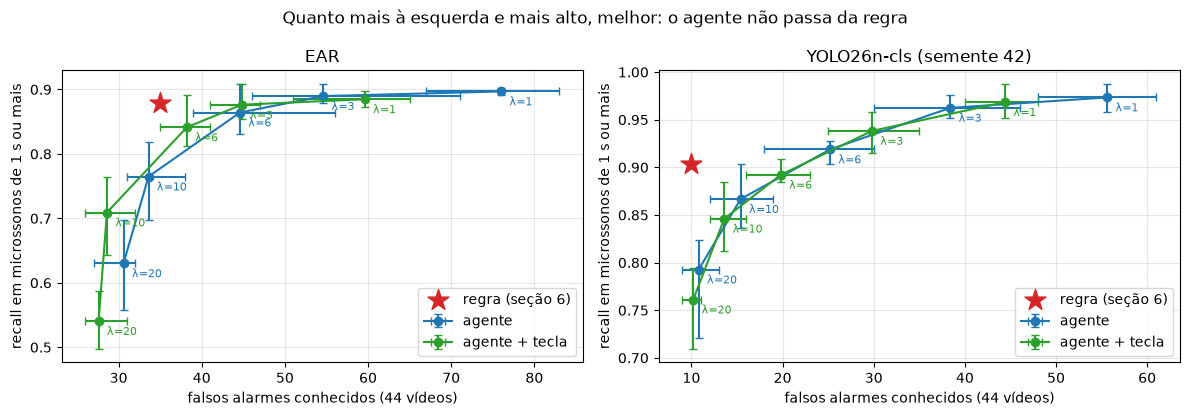

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cores = {"agente": "tab:blue", "agente + tecla": "tab:green"}
for ax, nome in zip(axes, SINAIS_RL):
    for versao, cor in cores.items():
        g = res_rl[(res_rl.sinal == nome) & (res_rl["versão"] == versao)].groupby("λ")
        m, lo, hi = g.mean(numeric_only=True), g.min(numeric_only=True), g.max(numeric_only=True)
        ax.errorbar(m.falsos, m["recall 1 s+"],
                    xerr=[m.falsos - lo.falsos, hi.falsos - m.falsos],
                    yerr=[m["recall 1 s+"] - lo["recall 1 s+"], hi["recall 1 s+"] - m["recall 1 s+"]],
                    fmt="o-", color=cor, capsize=3, label=versao)
        for lam, r in m.iterrows():
            ax.annotate(f"λ={lam}", (r.falsos, r["recall 1 s+"]), textcoords="offset points", xytext=(6, -10),
                        fontsize=8, color=cor)
    r = res_regra[nome]
    ax.scatter(r["falsos"], r["recall 1 s+"], marker="*", s=250, color="tab:red", zorder=5, label="regra (seção 6)")
    ax.set_xlabel("falsos alarmes conhecidos (44 vídeos)"); ax.set_ylabel("recall em microssonos de 1 s ou mais")
    ax.set_title(nome); ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.suptitle("Quanto mais à esquerda e mais alto, melhor: o agente não passa da regra")
plt.tight_layout(); plt.show()

### 7.2 O que o agente aprendeu

A tabela de um agente treinado nos 44 vídeos (EAR, λ = 6, semente 42) vira um mapa: cada célula é uma situação, e a cor é a ação escolhida. O mapa mostra só as situações sem aviso nos últimos 30 s, que são a grande maioria. Situações que o agente nunca viu ficam em "esperar", porque é o empate da tabela, e o piso de 3 s cobre esses casos.

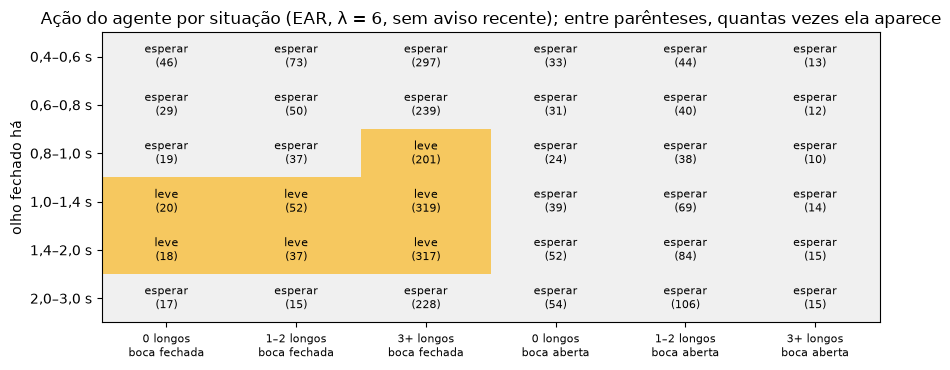

decisões nos 44 vídeos (sem aviso recente): 2,707 | situações que aparecem: 36 de 36 | trechos fechados de 0,4 s ou mais: 506


In [34]:
Q_mapa = treinar_agente(dados_rl["EAR"], recompensas(6), SEMENTE)

# quantas vezes cada situação aparece nos 44 vídeos (sem aviso recente)
visitas = np.zeros(N_ESTADOS, int)
for d in dados_rl["EAR"].values():
    for a, b in d["trechos"]:
        n_longos = int(((d["fim_longos"] < a) & (d["fim_longos"] >= a - JANELA_HIST)).sum())
        for n in range(INICIO, min(b - a + 1, PISO - 1) + 1, PASSO):
            visitas[estado(n / FPS, n_longos, d["boca"][a + n - 1], False)] += 1

faixas = ["0,4–0,6 s", "0,6–0,8 s", "0,8–1,0 s", "1,0–1,4 s", "1,4–2,0 s", "2,0–3,0 s"]
colunas = [(h, b) for b in (0, 1) for h in range(3)]
nomes_col = [f"{['0', '1–2', '3+'][h]} longos\n{'boca aberta' if b else 'boca fechada'}" for h, b in colunas]
idx_mapa = [[((d * 3 + h) * 2 + b) * 2 for h, b in colunas] for d in range(6)]
acao = np.array([[int(np.argmax(Q_mapa[s])) if visitas[s] else -1 for s in linha] for linha in idx_mapa])
n_vis = np.array([[visitas[s] for s in linha] for linha in idx_mapa])

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.imshow(acao, cmap=ListedColormap(["#dddddd", "#f0f0f0", "#f6c85f", "#d1495b"]), vmin=-1, vmax=2, aspect="auto")
rotulos = {-1: "não visto", 0: "esperar", 1: "leve", 2: "forte"}
for i in range(acao.shape[0]):
    for j in range(acao.shape[1]):
        ax.text(j, i, f"{rotulos[acao[i, j]]}\n({n_vis[i, j]})", ha="center", va="center", fontsize=8)
ax.set_yticks(range(6), faixas); ax.set_xticks(range(len(colunas)), nomes_col, fontsize=8)
ax.set_ylabel("olho fechado há")
ax.set_title("Ação do agente por situação (EAR, λ = 6, sem aviso recente); entre parênteses, quantas vezes ela aparece")
plt.tight_layout(); plt.show()
print(f"decisões nos 44 vídeos (sem aviso recente): {visitas.sum():,} | situações que aparecem: {(visitas > 0).sum()} de "
      f"{N_ESTADOS // 2} | trechos fechados de 0,4 s ou mais: {sum(len(d['trechos']) for d in dados_rl['EAR'].values())}")

### Observações do agente

- **O agente não superou a regra.** Em nenhum λ ele fica ao mesmo tempo à esquerda e acima da estrela. Com o YOLO, no mesmo nível de falsos alarmes da regra (cerca de 11, λ = 20), ele acha 131 de 165 microssonos, contra 149 da regra. Com o EAR, no mesmo nível (cerca de 34, λ = 10), acha 126 contra 145.
- **O que ele aprendeu faz sentido** (mapa acima). Ele nunca avisa com a boca aberta, ou seja, redescobriu sozinho o filtro de bocejo. Avisa a partir de 1 s, como o Euro NCAP. E avisa mais cedo, com 0,8 s, quando a pessoa já teve 3 ou mais fechamentos longos no último minuto, o único uso do histórico que a regra não tem. Entre 2 e 3 s, com a boca fechada, ele volta a esperar, provavelmente porque só chega ali sem aviso o trecho que passou a maior parte do tempo de boca aberta. O piso de 3 s cobre esses casos.
- **Menos avisos fortes à toa, mas com custo.** A regra só dá aviso forte. Com o YOLO e λ = 10, o agente dá 15 falsos alarmes, dos quais só 4 fortes, contra 10 fortes da regra, mas acha 143 microssonos em vez de 149.
- **A tecla "foi alarme falso" vai na direção certa:** no mesmo λ, ela tira de 6% a 22% dos falsos alarmes. O custo costuma ser de 1 a 5 acertos, mas chega a 15 com o EAR e λ = 20. Os vídeos duram de 20 s a 2 min, então cada pessoa dá poucos retornos. O efeito real só apareceria com uso longo da mesma pessoa.
- **Por que a regra ganha:** ela já usa as duas informações que mais importam (tempo de olho fechado e boca), e o agente aprende com cerca de 500 trechos fechados de 0,4 s ou mais. Os resultados também variam bastante entre sementes (barras do gráfico).
- **O piso de 3 s é barato com o YOLO e caro com o EAR.** Por construção, ele só dispara em trechos de 3 s ou mais em que o filtro de bocejo segurou o aviso. Com o YOLO, isso acontece 2 vezes nos 44 vídeos. Com o EAR, que usa um limiar de olho mais baixo, acontece 22 vezes, e por isso a regra do EAR aqui tem 21 alarmes (falsos ou sem rótulo) a mais do que na seção 6.2. Para manter o piso, que protege quem dorme de boca aberta, o YOLO é o sinal certo.
- **Limites:** os mesmos das seções anteriores (base sem identificador de motorista, buracos longos sem rótulo, vídeos que parecem seguir roteiro). Além disso, o vídeo gravado não reage ao aviso, então o agente aprende quando avisar, mas não o efeito do aviso.

**Decisão sugerida:** para a demo, manter a regra (YOLO, T = 1 s, filtro de bocejo e piso de 3 s ignorando o filtro). O agente fica como experimento, que mostra que RL redescobre as regras sensatas e usa o histórico da pessoa, mas que precisa de mais dados por pessoa para ganhar da regra.

## 8. Resumo e próximos passos

| Etapa | Resultado no teste |
|---|---|
| MediaPipe no FL3D | Rosto em 98,5% dos frames, de 10 a 24 ms por frame na CPU |
| EAR por frame (microssono) | AUC-PR 0,66 · F1 0,66 |
| CNN no MRL (8 pessoas novas) | Acurácia 97,0% · F1 0,969 · pior pessoa 91,9% |
| CNN no FL3D por frame | AUC-PR 0,76 · F1 0,75 |
| Alerta com T = 1 s, EAR | 7 de 26 episódios (7 de 14 com 1 s ou mais); 3 falsos alarmes |
| Alerta com T = 1 s, CNN | 13 de 26 episódios (13 de 14 com 1 s ou mais); 6 falsos alarmes |
| Validação cruzada nos 44 vídeos, EAR com mediana | 130 de 165 episódios de 1 s ou mais (79%); 30 falsos alarmes |
| Validação cruzada nos 44 vídeos, MobileNetV3 (5 sementes) | 73,5% dos episódios de 1 s ou mais; 41 falsos alarmes |
| Validação cruzada nos 44 vídeos, YOLO26n-cls (5 sementes) | 84,5% dos episódios de 1 s ou mais; 33 falsos alarmes |
| Validação cruzada, EAR com filtro de bocejo | 85,5% dos episódios de 1 s ou mais; 16 falsos alarmes |
| Validação cruzada, YOLO26n-cls com filtro de bocejo (5 sementes) | 86,8% dos episódios de 1 s ou mais; 10 falsos alarmes |
| Linha do tempo completa, YOLO com filtro (46 min, 1 semente) | 27 alarmes: 10 fora de buracos longos, 17 em buracos longos sem rótulo |
| Agente de RL, YOLO, λ = 10 (5 sementes; linha do tempo completa) | 143 de 165 episódios de 1 s ou mais (87%); 15,4 falsos alarmes (4,2 fortes), contra 149 e 10 da regra com piso |
| Agente de RL, EAR, λ = 6 (5 sementes; linha do tempo completa) | 142,6 de 165 (86%); 44,6 falsos alarmes, contra 145 e 35 da regra com piso |

**Conclusão:** o caminho completo, do vídeo ao alerta, funciona com T = 1 s. Na validação cruzada, o sistema acha cerca de 86% dos episódios de 1 s ou mais com o filtro de bocejo, com EAR ou YOLO, e os falsos alarmes caem de 33 para 10 no YOLO. O YOLO supera a MobileNet, mas ainda não supera o EAR de forma conclusiva. T = 1 s parece segurar a maioria das piscadas, mas a taxa real de falso alarme ainda não está medida: sobram alarmes em trechos que a base removeu e não rotulou. O holdout é pequeno (2 vídeos com microssono), 2 dos 5 motoristas também aparecem no treino dos autores do FL3D, e a base não mostra microssono junto de bocejo, que é o maior risco do filtro. O agente de RL (seção 7) aprende sozinho a ignorar o bocejo e a usar o histórico da pessoa, mas não supera a regra com estes dados.

**Próximos passos até 17/11:**

1. **Modelo temporal:** GRU ou TCN sobre a série de P(fechado), treinada no UTA-RLDD recortado (Kaggle) com separação por pessoa, para a sonolência na janela de 30 a 60 s.
2. **Recorte do olho:** alinhar pela linha dos olhos e medir de novo quando a cabeça cai.
3. **Domínio RGB:** juntar ao treino uma base RGB de olhos (por exemplo, CEW) e comparar com o MRL sozinho.
4. **Demo com webcam:** os três níveis do Euro NCAP com T = 1 s e estado "sem rosto visível".
5. **Piso de 3 s:** aplicar o piso ignorando o filtro de bocejo, como na seção 7, para não deixar sem alarme quem dorme de boca aberta. Com o YOLO, custa 2 alarmes nos 44 vídeos.
6. **Falsos alarmes reais:** gravações curtas do grupo, encenadas, na mesa ou em carro **desligado e parado**, com piscadas, conversa, olhares para baixo e bocejos com olho fechado. Essas gravações servem só para teste, e a pesquisa pede consultar o orientador sobre LGPD e ética antes de gravar.
7. **Agente de RL:** treinar e testar de novo com as gravações do grupo, que têm muitos minutos da mesma pessoa, e começar a tabela a partir da regra em vez de zero.